# zf1 — Measure

`metadata.hera.policy` — scientific record: append new cells; never edit or
delete executed ones. (Who *executes* a measure cell is set by the session
mode — see the brief.)

Confirm each `# <-- verify` (rig: addresses) and `# <-- validate` (device:
operating limits, wiring) line at bring-up. Cells marked **PATTERN** /
**PROPOSAL** carry `<PLACEHOLDER>` values — review before running.

## Setup

In [1]:
import os
import time

import numpy as np
import scipy.constants as cst

import qcodes
from qcodes import validators
from qcodes.instrument_drivers.stanford_research import SR830, SR860
from qcodes.instrument_drivers.Keithley import Keithley2400
from qcodes.instrument_drivers.american_magnetics import AMIModel430

import sweep

from hera.analysis import GateCalibration, field_invB

from sharpelab_nb.constants import TOPLOADER
from sharpelab_nb.thermometry import temperature_from_logfile
from sharpelab_nb.drivers import SRS_DC205

In [2]:
main_dir = os.getcwd()
sweep.set_basedir(os.path.join(main_dir, "data"))
main_dir

'C:\\Users\\toploader\\measurements\\aaron\\20260621-zf1'

# Connect Instruments

## Magnet

In [3]:
MAGNET_ADDR = "TCPIP0::192.168.0.101::7180::SOCKET"  # <-- verify address
magnet = AMIModel430("magnet", address=MAGNET_ADDR)
# Field in Tesla; magnet.field() is the MEASURED readback (coil constant
# 0.116783 T/A is configured on the unit). magnet.field(target) BLOCKS until
# the supply reports holding; a kernel interrupt does NOT stop the ramp.
magnet.field()

Connected to: AMERICAN MAGNETICS INC. 430 (serial:430-11-044, firmware:2.65) in 1.04s


-1.9208e-05

## Thermometry (file-based) + sample heater

Kernel temperature reads are **file-based**, not GPIB — the AVS bridge workers
own the bridges and write the logfiles. `temperature` is the loaded probe's
mixing chamber; the logfile path is **probe-dependent** (Probe1 = straight,
Probe2 = rotator). The sample heater is an **open-loop** Keithley voltage
source — set `heater.volt`, settle, then read T back from `temperature()`.

In [4]:
# Probe MC (sample T) — point at the LOADED probe (Probe1 straight / Probe2 rotator)
temperature = temperature_from_logfile(
    "T", r"C:\Users\toploader\temperature_logs\Probe2_MixingCh_low.txt")  # <-- verify probe
fridge_temperature = temperature_from_logfile("T_fridge", TOPLOADER.temp_logfiles["T_fridge"])
mag_temperature = temperature_from_logfile("T_magnet", TOPLOADER.temp_logfiles["T_magnet"])
print("probe MC:", temperature(), "K")

# Sample-stage heater — open-loop voltage drive (V->T is per-cooldown; device card)
heater = Keithley2400("heater", "GPIB4::12::INSTR")  # <-- verify address
heater.mode.set("VOLT")
heater.volt.step = 0.005

probe MC: 0.0337 K
Connected to: KEITHLEY INSTRUMENTS INC. 2400 (serial:1299232, firmware:C30   Mar 17 2006 09:29:29/A02  /K/J) in 0.10s


## Lock-ins

In [5]:
sr830_1 = SR830("sr830_1", "GPIB0::8::INSTR")  # <-- verify — current channel (Ithaco 1211 preamp output)
sr830_2 = SR830("sr830_2", "GPIB0::9::INSTR")  # <-- verify
sr830_3 = SR830("sr830_3", "GPIB0::4::INSTR")  # <-- verify
sr830_4 = SR830("sr830_4", "GPIB0::1::INSTR")  # <-- verify
sr830_5 = SR830("sr830_5", "GPIB0::5::INSTR")  # <-- verify
sr830_6 = SR830("sr830_6", "GPIB0::6::INSTR")  # <-- verify
sr830_7 = SR830("sr830_7", "GPIB0::7::INSTR")  # <-- verify
# sr830_8 = SR860("sr830_8", "TCPIP::192.168.0.107::inst0::INSTR")  # <-- verify — SR860; enable if used

C:\Users\toploader\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch1_databuffer on instrument sr830_1 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(
C:\Users\toploader\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch2_databuffer on instrument sr830_1 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(
C:\Users\toploader\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch1_databuffer on instrument sr830_2 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(
C:\Users\toploader\measurement_env\.venv\Lib\site-packages

Connected to: Stanford_Research_Systems SR830 (serial:s/n45469, firmware:ver1.07) in 0.13s
Connected to: Stanford_Research_Systems SR830 (serial:s/n45595, firmware:ver1.07) in 0.09s
Connected to: Stanford_Research_Systems SR830 (serial:s/n45471, firmware:ver1.07) in 0.10s


C:\Users\toploader\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch1_databuffer on instrument sr830_4 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(
C:\Users\toploader\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch2_databuffer on instrument sr830_4 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(
C:\Users\toploader\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch1_databuffer on instrument sr830_5 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(
C:\Users\toploader\measurement_env\.venv\Lib\site-packages

Connected to: Stanford_Research_Systems SR830 (serial:s/n43722, firmware:ver1.07) in 0.09s
Connected to: Stanford_Research_Systems SR830 (serial:s/n45470, firmware:ver1.07) in 0.09s
Connected to: Stanford_Research_Systems SR830 (serial:s/n43721, firmware:ver1.07) in 0.09s
Connected to: Stanford_Research_Systems SR830 (serial:s/n41621, firmware:ver1.07) in 0.09s


C:\Users\toploader\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch1_databuffer on instrument sr830_7 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(
C:\Users\toploader\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch2_databuffer on instrument sr830_7 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(


## Keithleys (gates)

In [6]:
# Gate Keithleys are role-named on this rig (k_tg/k_bg drive top/back gates),
# so recipes' k_tg / k_bg resolve directly. The third Keithley's role is
# per-insert (Si gate, or a probe-specific winding). Defaults: rangev 21,
# rangei 1uA, compliance 10 nA / 20 V, step 5 mV.
def _setup_k2400(k):
    # k.mode.set("VOLT")
    # k.rangev.set(21)
    # k.rangei.set(1e-6)
    # k.compliancev.set(20)
    # k.compliancei.set(1e-8)
    k.volt.step = 0.005
    return k

k_tg  = _setup_k2400(Keithley2400("k_tg",  "GPIB4::9::INSTR"))   # <-- verify — top gate
k_bg  = _setup_k2400(Keithley2400("k_bg",  "GPIB4::10::INSTR"))  # <-- verify — back gate
k_tg2 = _setup_k2400(Keithley2400("k_tg2", "GPIB4::11::INSTR"))  # <-- verify — third Keithley (per-insert role)

Connected to: KEITHLEY INSTRUMENTS INC. 2400 (serial:4028439, firmware:C32   Oct  4 2010 14:20:11/A02  /T/K) in 0.03s
Connected to: KEITHLEY INSTRUMENTS INC. 2400 (serial:4028442, firmware:C32   Oct  4 2010 14:20:11/A02  /T/K) in 0.02s
Connected to: KEITHLEY INSTRUMENTS INC. 2400 (serial:4028489, firmware:C32   Oct  4 2010 14:20:11/A02  /T/K) in 0.03s


## DC205 (DC current bias)

On the toploader, gates are Keithleys; the DC205s are **DC current-bias**
sources (through a 100 MΩ series resistor — see the device card). Set
`volt -> 0` before reconfiguring or ending a measurement.

In [7]:
dc205_1 = SRS_DC205("dc205_1", "ASRL6::INSTR")  # <-- verify address — DC current bias
dc205_1.volt = dc205_1.voltage
dc205_1.volt.step = 0.005

dc205_3 = SRS_DC205("dc205_3", "ASRL7::INSTR")  # <-- verify address — second DC205
dc205_3.volt = dc205_3.voltage
dc205_3.volt.step = 0.005

Connected to: Stanford_Research_Systems DC205 (serial:s/n20500516, firmware:ver1.80) in 0.02s
Connected to: Stanford_Research_Systems DC205 (serial:s/n20500513, firmware:ver1.80) in 0.03s


# SAFETIES

Run immediately after instrument bring-up, before any sweep.

In [8]:
# slot: gate-validators — operating limits from the device card's gate-
# operating-limits table; commit EXACTLY the card numbers. Each value
# `# <-- validate`.
TG_MIN, TG_MAX = -7.0, +6.0   # top gate (k_tg), V    # <-- validate
BG_MIN, BG_MAX = -4.0, +4.2   # back gate (k_bg), V    # <-- validate
k_tg.volt.vals = validators.Numbers(TG_MIN, TG_MAX)
k_bg.volt.vals = validators.Numbers(BG_MIN, BG_MAX)

# Limit lists for sanitize_tg_bg()
tg_lims, bg_lims = [TG_MIN, TG_MAX], [BG_MIN, BG_MAX]

# Session field cap — machine-enforced: magnet.field is a qcodes Parameter, so
# this validator rejects magnet.field(target) with |B| > cap before any
# hardware traffic. Driver backstop: |B| <= COIL? x current_limit (~9 T) on the
# AMI430 unit.
B_SESSION_CAP = 0.1  # Tesla    # <-- validate (session cap from brief: |B| <= 100 mT)
magnet.field.vals = validators.Numbers(-B_SESSION_CAP, B_SESSION_CAP)

# Sample-heater ceiling for sustained runs (V, not T — open-loop drive).
HEATER_V_MAX = 6.5  # V    # <-- validate
heater.volt.vals = validators.Numbers(0, HEATER_V_MAX)

# DC current-bias range (SRS DC205 hardware: +/-15 V -> +/-150 nA at 100 MOhm).
dc205_1.volt.vals = validators.Numbers(-15, 15)


# Helpers

In [9]:
def spoints(a, b, c):
    return np.linspace(a, b, c)


def sanitize_tg_bg(vtg_vec, vbg_vec, tg_lims, bg_lims):
    """
    Given a list of tg and bg voltages, removes any points which are outside tg_lims and bg_lims
    """
    vtg_new_vec = []
    vbg_new_vec = []
    for ind in range(len(vtg_vec)):
        vtg, vbg = vtg_vec[ind], vbg_vec[ind]
        if vtg < tg_lims[0] or vtg > tg_lims[1] or vbg < bg_lims[0] or vbg > bg_lims[1]:
            pass
        else:
            vtg_new_vec.append(vtg)
            vbg_new_vec.append(vbg)
    return np.array(vtg_new_vec), np.array(vbg_new_vec)

In [10]:
# slot: geometry — gate-stack thicknesses from the device card's Gate-stack
# geometry (geometry prior — calibrate cnp-and-dline-calibration before
# trusting derived scales). Each value `# <-- validate`.
t_tg = 23.6e-9   # top-gate hBN thickness, m    # <-- validate
t_bg = 20e-9     # back-gate hBN thickness, m    # <-- validate
t_bgSiO2 = 0     # SiO2 term, m — zero for a metal/graphite back gate    # <-- validate

# Session gate calibration. cal.n_D(V_tg, V_bg) -> (n [m^-2], D [V/m]);
# set n_offset / D_offset from cnp-and-dline-calibration once live.
cal = GateCalibration.from_thicknesses(t_tg, t_bg, t_bgSiO2)

# Measurement config

In [11]:
# slot: meas-config — channel/contact assignments + gains from the device
# card's Measurement setup (current channel + gain, provided contact
# configuration). Each value `# <-- validate`. Toploader contacts are wired
# DIRECT (no QSwitch) — name the contact pair per channel. Always set 'comment'
# per run — structured, current, no inherited text.
meas_config = {
    "sr1": "5-4",   "sr1_gain": -1e6,   # current channel (Ithaco 1211)    # <-- validate
    "sr2": "5-4",   "sr2_gain": 1e2,    # 2T voltage    # <-- validate
    "sr3": "30-31", "sr3_gain": 1e2,    # 4T longitudinal    # <-- validate
    "bias_resistor": 1e8,
    "bias_voltage_1": sr830_1.amplitude(),
    "lockin_freq_1": sr830_1.frequency(),
    "comment": "<SET PER RUN>",
}


# HERA — session start (2026-06-21)

## HERA — Gate C: contact-wiring liveness check (first session)

Bring-up is green: setup cells executed in-kernel, SAFETIES committed and matching the device card exactly (TG (−7,+6) V, BG (−4,+4.2) V, field cap 0.1 T, heater 6.5 V); magnet reads −0.02 mT, probe MC 33.7 mK. Before the multi-hour pristine-field map I want a cheap liveness check on the provided wiring — recipe `measurements/contact-survey-2t.md` (B=0 aliveness flavor), pre-(n,D)-cal **raw single-gate** variant since the cap ratio isn't pinned yet. A single **BG cut at TG=0** across the full BG validator, reading the provided config: sr1 (5-4, current), sr2 (5-4, 2T), sr3 (30-31, 4T longitudinal), plus both gate leakage currents.

This rig is **current-bias** (0.1 V / 100 MΩ ≈ 1 nA): the current channel only separates dead/alive (pinned at I_bias for any live pair), so the CNP and Rxx come from the **4T channel sr3**. Crossing the CNP (expected near BG≈0 at TG=0, slope prior −1.18) proves the 4T channel is live and the device gates; a flat/zero sr3 or a current far from ~1 nA is a wiring fault to chase before committing map time.

**Before running, eyeball the precondition print** — T at base, B≈0, gates read sane; the cell raises on mismatch. It zeroes the DC bias and **does not touch the field controller** (Step-1 map-before-energise discipline). Coverage trade: TG fixed at 0 → one CNP crossing only; the full (n,D) survey is the next step, this is aliveness only. ~3–4 min + BG ramp.


T(probe MC) = 33.7 mK   (expect base, mK range)
B           = -0.022 mT   (expect ~0; field controller NOT touched)
gates now   : TG=0.000 V   BG=0.000 V
lock-in tc  : sr1=300 ms  sr2=300 ms  sr3=300 ms
AC drive    : 0.004 V @ 7.777 Hz  (-> ~1 nA through 100 MOhm)
BG cut: -4.0 -> 4.2 V, 141 pts, delay=1.50s  (~5.9 min + ramp)
2026-06-21 14:13:54,835 [INFO] Ramping dc205_1_voltage: 0.0 -> 0
2026-06-21 14:13:54,898 [INFO] Ramping k_tg_volt: 0.0 -> 0.0
2026-06-21 14:13:54,960 [INFO] Ramping k_bg_volt: 0.0 -> -4.0
2026-06-21 14:14:05,072 [INFO] Starting sweep with ID 0
2026-06-21 14:14:05,073 [INFO] Minimum duration 0h 3m 31s


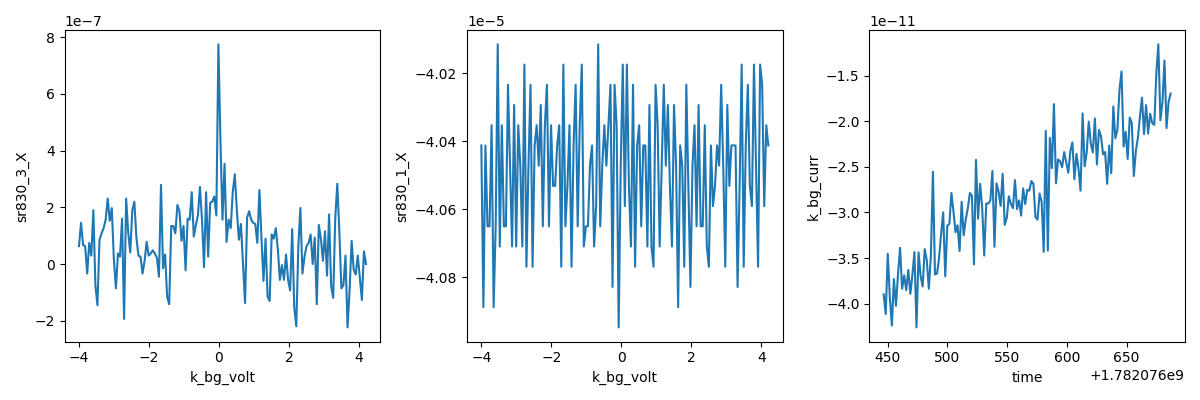

2026-06-21 14:18:07,488 [INFO] Completed in 0h 4m 1s
2026-06-21 14:18:07,488 [INFO] Data saved in C:\Users\toploader\measurements\aaron\20260621-zf1\data\0\data.tsv.gz
2026-06-21 14:18:07,550 [INFO] Ramping k_bg_volt: 4.2 -> 0.0


In [12]:
# Gate C — contact-wiring liveness check (first session).
# Governing recipe: measurements/contact-survey-2t.md (B=0 aliveness flavor).
# Pre-(n,D)-cal RAW single-gate cut: sweep BG across its full validator at
# TG=0, reading the provided config channels + gate leakage. Current-bias rig
# (~1 nA through 100 MOhm) -> current channel separates dead/alive only; the
# CNP / Rxx read comes from the 4T voltage channel sr3 (30-31).
import numpy as np, time

# ---- preconditions: state this cell assumes but does NOT set ----
T = temperature()
B = magnet.field()
vtg0, vbg0 = k_tg.volt(), k_bg.volt()
tc1, tc2, tc3 = sr830_1.time_constant(), sr830_2.time_constant(), sr830_3.time_constant()
amp, frq = sr830_1.amplitude(), sr830_1.frequency()
print(f"T(probe MC) = {T*1e3:.1f} mK   (expect base, mK range)")
print(f"B           = {B*1e3:.3f} mT   (expect ~0; field controller NOT touched)")
print(f"gates now   : TG={vtg0:.3f} V   BG={vbg0:.3f} V")
print(f"lock-in tc  : sr1={tc1*1e3:.0f} ms  sr2={tc2*1e3:.0f} ms  sr3={tc3*1e3:.0f} ms")
print(f"AC drive    : {amp} V @ {frq} Hz  (-> ~1 nA through 100 MOhm)")
assert T < 0.08, f"T not at base: {T*1e3:.1f} mK"
assert abs(B) < 0.01, f"B unexpectedly large: {B*1e3:.3f} mT"

# ---- sweep design ----
delay = max(0.2, 5*max(tc1, tc2, tc3))   # dwell >= ~5*tau (STYLE settling floor)
N = 141
bg_lo, bg_hi = -4.0, 4.2                  # full BG validator (-4, +4.2)
bg_vec = np.linspace(bg_lo, bg_hi, N)
print(f"BG cut: {bg_lo} -> {bg_hi} V, {N} pts, delay={delay:.2f}s  "
      f"(~{N*(delay+1.0)/60:.1f} min + ramp)")

mc = dict(meas_config)
mc["bias_voltage_1"] = sr830_1.amplitude()
mc["lockin_freq_1"]  = sr830_1.frequency()
mc["comment"] = ("Gate C liveness: raw BG cut at TG=0, full BG validator, B~0; "
                 "sr1=5-4(I) sr2=5-4(2T) sr3=30-31(4T longitudinal)")

s = sweep.AsyncStation(mc)
s.add_comment('contact-survey-2t')
s.add_comment('Gate C liveness — raw BG cut, TG=0, pre-(n,D)-cal, first session')

# AC-only liveness: zero DC bias, park TG, position BG at start
s.ramp(dc205_1.volt, 0)
s.ramp(k_tg.volt, 0.0)
s.ramp(k_bg.volt, bg_lo)
time.sleep(5)

s.fp(temperature).fp(fridge_temperature)
s.fp(k_tg.volt).fp(k_tg.curr).fp(k_bg.volt).fp(k_bg.curr)
s.fp(sr830_1.X).fp(sr830_1.P)
s.fp(sr830_2.X).fp(sr830_2.P)
s.fp(sr830_3.X).fp(sr830_3.P)
s.plot(k_bg.volt, sr830_3.X)   # 4T voltage vs BG -> CNP peak
s.plot(k_bg.volt, sr830_1.X)   # current channel -> pinned-at-I_bias check
s.plot('time', k_bg.curr)      # live BG leakage

s.sweep(k_bg.volt, bg_vec, delay=delay)

# park back gate
s.ramp(k_bg.volt, 0.0)


## HERA — 1 nA confirmation cut (validate 4T SNR before the survey map)

Gate C passed at 40 pA: current path 5-4 alive (pinned at I_bias), 2T 5-4 a clean CNP (42.7 kΩ at BG = −0.017 V), and the 4T channel sr3 (30-31) is **real** — its smoothed CNP coincides with the 2T CNP — but starved to 2–8 nV (SNR ~2–3) by the low drive. Leakage healthy (|I_tg|≤57 pA, |I_bg|≤43 pA). Per your call, raising the AC drive to the device-card nominal **0.1 V / 1 nA** and re-ranging the lock-ins, then repeating the same BG cut as a direct before/after on the 4T SNR.

**Sensitivities I've set** (signals scale 25×): sr1 (current) 2 mV [≈1 mV signal], sr2 (2T) 100 µV [CNP ≈43 µV], sr3 (4T) 20 µV — tuned for the **low-Rxx / metallic regime** where SC candidates live; the CNP peak may clip, which is fine (we don't need CNP Rxx). **Eyeball the live monitor for overload** on the first few points and stop/adjust if any channel rails.

**Success criterion:** sr3 (4T) shows a clean CNP feature ~25× above the run-0 noise and a readable metallic baseline. If it does, the next proposal is the pristine-field axis-aligned survey gatemap reusing these exact settings (it doubles as the cap-ratio / CNP-slope substrate, investigation Step 1). If sr3 is still ugly at 1 nA, the 30-31 pair is suspect (note: device-card active-pairs lists 7-31, not 30-31) and I'll propose trying 7-31. Does **not** touch the field controller. ~3–4 min + ramp.


T = 33.7 mK   B = 0.031 mT   gates TG=0.000 BG=0.000
AC drive now = 0.004 V (raising to 0.1 V)
amp: 0.1  sens: 0.002 0.0001 2e-05
BG cut -4 -> 4.2 V, 141 pts, delay=1.50s (~5.9 min + ramp)
2026-06-21 14:29:20,992 [INFO] Ramping dc205_1_voltage: 0.0 -> 0
2026-06-21 14:29:21,053 [INFO] Ramping k_tg_volt: 0.0 -> 0.0
2026-06-21 14:29:21,115 [INFO] Ramping k_bg_volt: 0.0 -> -4.0
2026-06-21 14:29:31,215 [INFO] Starting sweep with ID 1
2026-06-21 14:29:31,216 [INFO] Minimum duration 0h 3m 31s


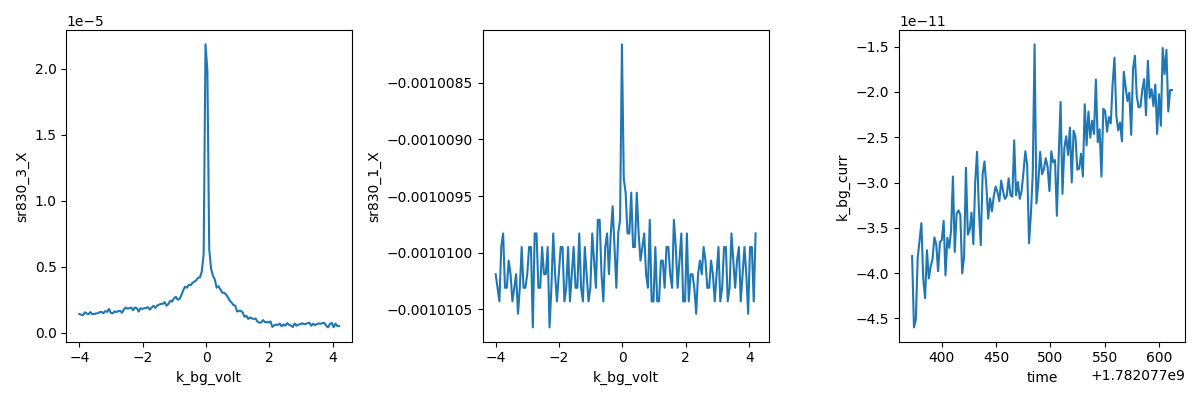

2026-06-21 14:33:32,589 [INFO] Completed in 0h 4m 0s
2026-06-21 14:33:32,590 [INFO] Data saved in C:\Users\toploader\measurements\aaron\20260621-zf1\data\1\data.tsv.gz
2026-06-21 14:33:32,663 [INFO] Ramping k_bg_volt: 4.2 -> 0.0


In [13]:
# 1 nA confirmation cut — re-run the Gate C BG cut at the device-card nominal
# drive (0.1 V -> 1 nA) to validate 4T SNR and my lock-in sensitivity choices
# before the survey map. Direct before/after vs run 0 (40 pA). Recipe:
# contact-survey-2t (raw single-gate aliveness flavor).
import numpy as np, time

# ---- preconditions: state assumed but not set ----
T = temperature(); B = magnet.field()
vtg0, vbg0 = k_tg.volt(), k_bg.volt()
print(f"T = {T*1e3:.1f} mK   B = {B*1e3:.3f} mT   gates TG={vtg0:.3f} BG={vbg0:.3f}")
print(f"AC drive now = {sr830_1.amplitude()} V (raising to 0.1 V)")
assert T < 0.08, f"T not at base: {T*1e3:.1f} mK"
assert abs(B) < 0.01, f"B too large: {B*1e3:.3f} mT"

# ---- set drive + sensitivities for 1 nA (HERA-chosen, per operator) ----
s_drive = 0.1                  # 0.1 V -> 1 nA through 100 MOhm (device card)
sr830_1.amplitude(s_drive)
sr830_1.sensitivity(2e-3)      # current: 1 nA * 1e6 = 1 mV -> 2 mV range
sr830_2.sensitivity(1e-4)      # 2T: CNP ~43 uV -> 100 uV range
sr830_3.sensitivity(2e-5)      # 4T: tuned for the low-Rxx (metallic) regime;
                               #     CNP peak may clip (we don't need it for SC)
print("amp:", sr830_1.amplitude(), " sens:",
      sr830_1.sensitivity(), sr830_2.sensitivity(), sr830_3.sensitivity())

delay = max(0.2, 5*max(sr830_1.time_constant(),
                       sr830_2.time_constant(), sr830_3.time_constant()))
N = 141
bg_vec = np.linspace(-4.0, 4.2, N)
print(f"BG cut -4 -> 4.2 V, {N} pts, delay={delay:.2f}s "
      f"(~{N*(delay+1.0)/60:.1f} min + ramp)")

mc = dict(meas_config)
mc["bias_voltage_1"] = s_drive
mc["comment"] = ("1nA confirmation: raw BG cut TG=0, drive 0.1V/1nA, "
                 "sens sr1=2mV sr2=100uV sr3=20uV; validate 4T SNR vs run0(40pA)")

s = sweep.AsyncStation(mc)
s.add_comment('contact-survey-2t')
s.add_comment('1nA confirmation BG cut, TG=0 — validate 4T SNR for survey map')

s.ramp(dc205_1.volt, 0)        # AC-only
s.ramp(k_tg.volt, 0.0)
s.ramp(k_bg.volt, -4.0)
time.sleep(5)

s.fp(temperature).fp(fridge_temperature)
s.fp(k_tg.volt).fp(k_tg.curr).fp(k_bg.curr)   # not k_bg.volt (swept, auto-recorded)
s.fp(sr830_1.X).fp(sr830_1.P)
s.fp(sr830_2.X).fp(sr830_2.P)
s.fp(sr830_3.X).fp(sr830_3.P)
s.plot(k_bg.volt, sr830_3.X)   # 4T vs BG -> should now show a clean CNP
s.plot(k_bg.volt, sr830_1.X)   # current (pinned ~1 nA)
s.plot('time', k_bg.curr)      # live leakage

s.sweep(k_bg.volt, bg_vec, delay=delay)
s.ramp(k_bg.volt, 0.0)


## HERA — pristine-field survey gate map (investigation Step 1)

1 nA validation done: **4T sr3 (30-31) is the campaign's Rxx channel** — clean CNP at BG=−0.017 V, SNR ~108, metallic resolved to ~6 Ω. (2T sr2 saturates at 1 nA from drive feedthrough on injection node 5 — coarse range, cross-check only; logged.) Now the first science step: an **axis-aligned (V_tg, V_bg) survey megasweep at B=0**, recipes `gatemap.md` + `cnp-and-dline-calibration.md`, doing double duty per the investigation — (1) candidate low-Rxx overview, (2) the CNP-slope substrate to pin the cap ratio (the device-card geometry is only a prior).

**Coarse reconnaissance, by design.** Full validator box (TG −7→+6 slow, BG −4→+4.2 fast), 81×121, tc dropped to 100 ms to make it affordable. BG step ≈ 68 mV ≈ Δn 6×10¹⁰ cm⁻² — enough to map the CNP line and broad candidate regions, **not** to resolve the ~5×10¹⁰-wide SC arc. That's intentional: the narrow arc gets located by n-linecuts and a tight nD polygon map next (investigation Step 1 heuristic-zoom). **Est ~1.4 h.**

**Field discipline:** B=0 (reads 0.03 mT), magnet controller untouched — this map must precede energising (Step-1 map-before-energise). The cell asserts B≈0 and T base before moving gates; it starts at the most-negative TG corner (highest leakage risk) so the checkpoint sees the worst case first.

**Checkpoint (~17 min, TG row ~15/81):** I'll read partial data — gate leakage staying < 100 pA, the 4T CNP ridge tracking sensibly, and the actual row rate vs estimate. Continue / adjust-range / abort fork stated there; an early wash-out saves ~1 h. I'm arming a background `hera-watch` monitor when this lands. Gates park to 0 at the end.


T=33.7 mK  B=0.034 mT  TG=0.000 BG=0.000  amp=0.1 V
tc: 0.1  sens 1/2/3: 0.002 0.002 5e-06
map 81x121 (TG slow / BG fast), est ~1.4 h
2026-06-21 14:42:21,713 [INFO] Ramping dc205_1_voltage: 0.0 -> 0
2026-06-21 14:42:21,776 [INFO] Ramping k_tg_volt: 0.0 -> -7.0
2026-06-21 14:42:30,769 [INFO] Ramping k_bg_volt: 0.0 -> -4.0
2026-06-21 14:42:45,989 [INFO] Starting megasweep with ID 2
2026-06-21 14:42:45,989 [INFO] Minimum duration 0h 50m 21s


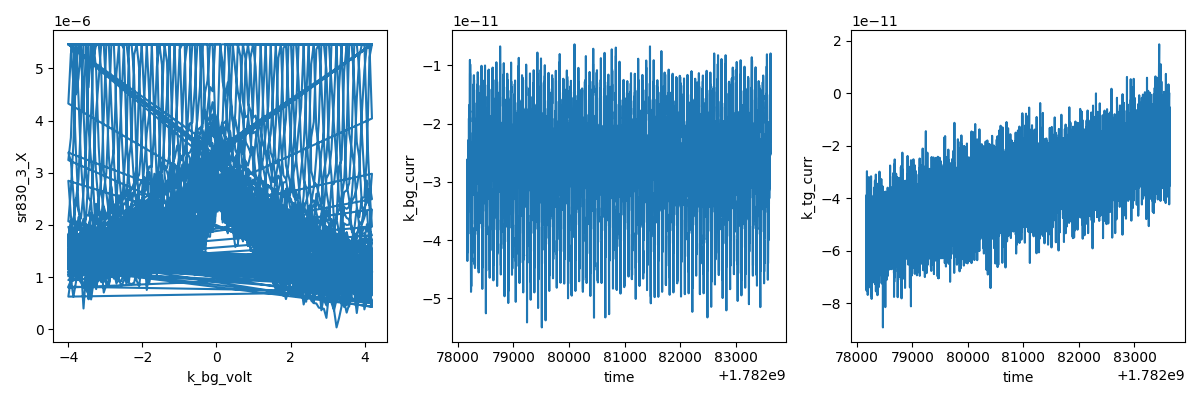

2026-06-21 16:13:57,463 [INFO] Completed in 1h 31m 10s
2026-06-21 16:13:57,464 [INFO] Data saved in C:\Users\toploader\measurements\aaron\20260621-zf1\data\2\data.tsv.gz
2026-06-21 16:13:57,527 [INFO] Ramping k_tg_volt: 6.0 -> 0.0
2026-06-21 16:14:05,137 [INFO] Ramping k_bg_volt: 4.2 -> 0.0


In [14]:
# Pristine-field survey gate map — investigation sc-characterization Step 1.
# Axis-aligned (V_tg, V_bg) megasweep at B=0: candidate low-Rxx overview AND
# the cap-ratio / CNP-slope substrate (cnp-and-dline-calibration). COARSE
# reconnaissance — resolve the CNP line + broad candidate regions; the narrow
# SC arc gets located by n-linecuts + a tight nD map next. Recipe: gatemap.md.
# 4T (sr3, 30-31) is the science channel (validated SNR~108 at 1 nA, run 1);
# 2T (sr2) saturates at 1 nA (drive feedthrough on injection node 5) -> coarse
# range, cross-check only.
import numpy as np, time

# ---- preconditions: assumed, not set ----
T = temperature(); B = magnet.field()
print(f"T={T*1e3:.1f} mK  B={B*1e3:.3f} mT  TG={k_tg.volt():.3f} BG={k_bg.volt():.3f}  amp={sr830_1.amplitude()} V")
assert T < 0.08, f"T not at base: {T*1e3:.1f} mK"
assert abs(B) < 0.01, f"B too large: {B*1e3:.3f} mT (survey map must precede energising the magnet)"

# ---- instrument settings (HERA-set; operator owns hands) ----
for sr in (sr830_1, sr830_2, sr830_3):
    sr.time_constant(0.1)          # 100 ms: ~3x faster map; 4T SNR still ~60
sr830_1.sensitivity(2e-3)          # current ~1 mV
sr830_2.sensitivity(2e-3)          # 2T saturates at 1 nA -> coarse range, cross-check only
sr830_3.sensitivity(5e-6)          # 4T: resolve low-Rxx (CNP ~218 nV, metallic ~6-20 nV)
print("tc:", sr830_3.time_constant(), " sens 1/2/3:",
      sr830_1.sensitivity(), sr830_2.sensitivity(), sr830_3.sensitivity())

# ---- map geometry (full validator box) ----
N_tg, N_bg = 81, 121
tg_vec = np.linspace(-7.0, 6.0, N_tg)      # full TG validator, SLOW axis
bg_vec = np.linspace(-4.0, 4.2, N_bg)      # full BG validator, FAST axis
fast_delay, slow_delay = 0.3, 1.0          # fast_delay = 3x tc
est_h = N_tg*(slow_delay + N_bg*(fast_delay+0.2))/3600
print(f"map {N_tg}x{N_bg} (TG slow / BG fast), est ~{est_h:.1f} h")

mc = dict(meas_config); mc["bias_voltage_1"] = sr830_1.amplitude()
mc["comment"] = ("survey gatemap B=0: TG[-7,6] x BG[-4,4.2] 81x121 coarse; "
                 "4T=sr3(30-31) primary tc=100ms; cap-ratio + candidate overview")

s = sweep.AsyncStation(mc)
s.add_comment('gatemap')
s.add_comment('cnp-and-dline-calibration')      # this map is the cap-ratio substrate
s.add_comment('pristine-field survey B=0 — first map before energising magnet')

s.ramp(dc205_1.volt, 0)
s.ramp(k_tg.volt, -7.0)
s.ramp(k_bg.volt, -4.0)
time.sleep(10)

s.fp(temperature).fp(fridge_temperature)
s.fp(k_tg.curr).fp(k_bg.curr)                   # leakage (not the swept volts)
s.fp(sr830_1.X).fp(sr830_1.P)
s.fp(sr830_2.X).fp(sr830_2.P)
s.fp(sr830_3.X).fp(sr830_3.P)
s.plot(k_bg.volt, sr830_3.X)                    # live 4T vs BG (CNP / candidate tracking)
s.plot('time', k_bg.curr)                       # live BG leakage
s.plot('time', k_tg.curr)                       # live TG leakage

s.megasweep(k_tg.volt, tg_vec, k_bg.volt, bg_vec,
            slow_delay=slow_delay, fast_delay=fast_delay)

s.ramp(k_tg.volt, 0.0); s.ramp(k_bg.volt, 0.0)


## HERA — n-linecuts at fixed D (locate / rule out the SC arc)

**Survey map (run 2) result:** clean, cap ratio **confirmed 1.189** (prior 1.180; CNP-slope fit, 17 mV residual) → (n, D) now calibrated (ratio data-grade; absolute scale still geometry-prior pending a QH lever arm; D_offset assumed 0). The coarse map shows **no obvious SC candidate** — the accessible hole-side high-|D| region is uniformly metallic ~20 Ω, no distinct low-Rxx pocket. But the map is coarse (Δn ≈ 6×10¹⁰ vs the ~5×10¹⁰ arc width) and only reaches |D| ≈ 0.76 V/nm at its corner, so a narrow arc could have been averaged out.

**This step** (investigation Step 1 heuristic-zoom): two **fine, high-SNR n-linecuts at fixed D** to resolve or rule out a narrow arc — D = **−0.60 V/nm** (the highest |D| with a full n-window inside the gate validators; D=−0.75 would need TG<−7) and **−0.45 V/nm**. Each scans n = +1 → −8×10¹¹ cm⁻² (wider than the nominal −4 to −6 band) at ~4×10⁹ cm⁻²/pt — ~12 points across a 5×10¹⁰ arc — with tc=300 ms (SNR ~20 on a 20 Ω metallic baseline), 1 nA, 4T sr3 (30-31). Two co-swept gate lines (`multisweep`); ~**4 min each, ~10 min total**.

**Reads:** a local Rxx dip below the metallic baseline within the n=−4 to −6 band = candidate → I follow with a tight nD map + bias spectroscopy. Flat metallic across both = no SC arc resolvable in the accessible (n, D), a meaningful (if D-limited) result. The scan crosses the CNP at n≈0 (gapped/insulating there — current drops, 4T ill-defined; ignore that point). B untouched. Precondition print asserts T base, B≈0 before gates move.


T=33.7 mK  B=0.013 mT  TG=0.000 BG=0.000  amp=0.1 V
tc: 0.3  sens: 0.002 0.002 5e-06
D=-0.60 V/nm: 200/200 pts, n=[+1.00,-8.00]e11, ~4.0 min
2026-06-21 16:25:52,504 [INFO] Ramping dc205_1_voltage: 0.0 -> 0
2026-06-21 16:25:52,565 [INFO] Ramping k_tg_volt: 0.0 -> -4.633544829207968
2026-06-21 16:25:58,536 [INFO] Ramping k_bg_volt: 0.0 -> 4.073267093891553
2026-06-21 16:26:11,660 [INFO] Starting multisweep with ID 3
2026-06-21 16:26:11,660 [INFO] Minimum duration 0h 3m 20s


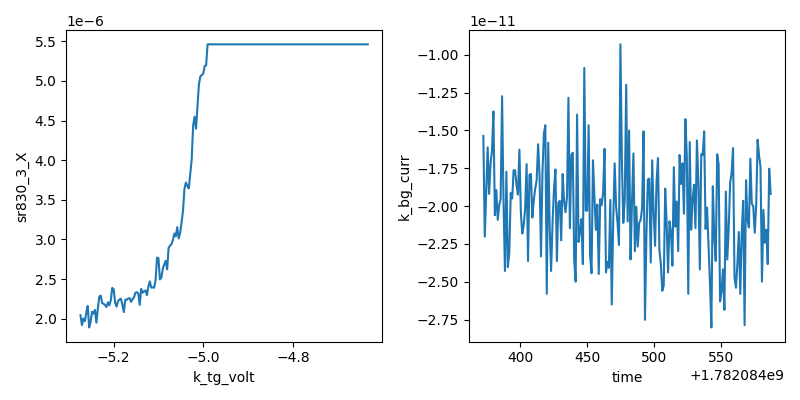

2026-06-21 16:29:47,544 [INFO] Completed in 0h 3m 35s
2026-06-21 16:29:47,545 [INFO] Data saved in C:\Users\toploader\measurements\aaron\20260621-zf1\data\3\data.tsv.gz
D=-0.45 V/nm: 200/200 pts, n=[+1.00,-8.00]e11, ~4.0 min
2026-06-21 16:29:47,565 [INFO] Ramping dc205_1_voltage: 0.0 -> 0
2026-06-21 16:29:47,627 [INFO] Ramping k_tg_volt: -5.274 -> -3.453544829207968
2026-06-21 16:29:50,025 [INFO] Ramping k_bg_volt: 3.5305 -> 3.0732670938915527
2026-06-21 16:29:58,627 [INFO] Starting multisweep with ID 4
2026-06-21 16:29:58,628 [INFO] Minimum duration 0h 3m 20s


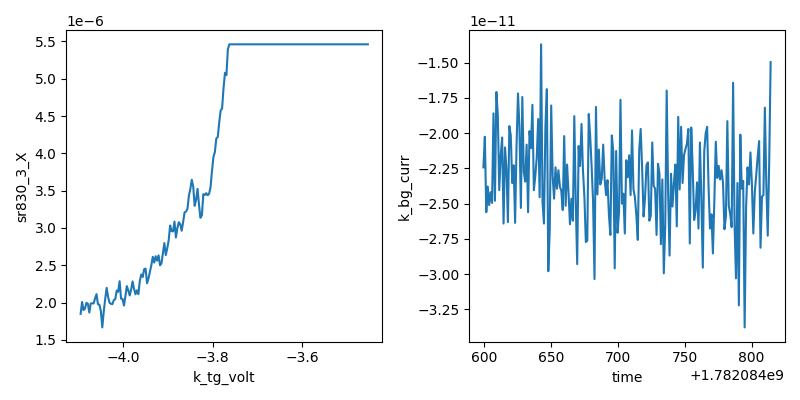

2026-06-21 16:33:34,721 [INFO] Completed in 0h 3m 35s
2026-06-21 16:33:34,721 [INFO] Data saved in C:\Users\toploader\measurements\aaron\20260621-zf1\data\4\data.tsv.gz
2026-06-21 16:33:34,790 [INFO] Ramping k_tg_volt: -4.094 -> 0.0
2026-06-21 16:33:40,070 [INFO] Ramping k_bg_volt: 2.5305 -> 0.0


In [15]:
# n-linecuts at fixed D (investigation Step 1 heuristic-zoom: locate the arc).
# Cap ratio confirmed 1.189 (CNP-slope fit, run 2); (n,D) now calibrated.
# Fine n-scan at high SNR on the hole side, high |D|, to RESOLVE or rule out a
# narrow SC arc that the coarse survey (Dn~6e10) could have averaged over.
# D=-0.60 is the highest |D| with a full n-window inside the gate validators
# (D=-0.75 would need TG<-7). 4T sr3 (30-31) is the Rxx channel.
# Recipe: cnp-and-dline-calibration (D-line design) + nD-map (co-swept line).
import numpy as np, time
import scipy.constants as cst

# ---- preconditions ----
T=temperature(); B=magnet.field()
print(f"T={T*1e3:.1f} mK  B={B*1e3:.3f} mT  TG={k_tg.volt():.3f} BG={k_bg.volt():.3f}  amp={sr830_1.amplitude()} V")
assert T<0.08, f"T not base {T*1e3:.1f} mK"
assert abs(B)<0.01, f"B too large {B*1e3:.3f} mT"

# ---- high-SNR settings ----
for sr in (sr830_1,sr830_2,sr830_3): sr.time_constant(0.3)
sr830_1.sensitivity(2e-3); sr830_2.sensitivity(2e-3); sr830_3.sensitivity(5e-6)
print("tc:",sr830_3.time_constant()," sens:",sr830_1.sensitivity(),sr830_2.sensitivity(),sr830_3.sensitivity())

# ---- calibrated (n,D) inverse (ratio 1.189; n_offset from CNP intercept b=+0.0259 V) ----
c_tg=cst.epsilon_0*3/23.6e-9; c_bg=cst.epsilon_0*3/20e-9
n_offset=-c_bg*0.0259/cst.e
def gates_for(n_cm,D_vnm):
    n=np.asarray(n_cm)*1e4; D=D_vnm*1e9
    a=(n-n_offset)*cst.e; bb=D*2*cst.epsilon_0
    return (a+bb)/(2*c_tg),(a-bb)/(2*c_bg)
def n_of(vtg,vbg):
    return ((c_tg*np.asarray(vtg)+c_bg*np.asarray(vbg))/cst.e + n_offset)*1e-4  # cm^-2

delay=1.0; N=200
for D in (-0.60,-0.45):
    n_req=np.linspace(1e11,-8e11,N)
    vtg,vbg=gates_for(n_req,D)
    vtg2,vbg2=sanitize_tg_bg(vtg,vbg,tg_lims,bg_lims)
    nr=n_of(vtg2,vbg2)
    print(f"D={D:+.2f} V/nm: {len(vtg2)}/{N} pts, n=[{nr.max()/1e11:+.2f},{nr.min()/1e11:+.2f}]e11, "
          f"~{len(vtg2)*(delay+0.2)/60:.1f} min")
    mc=dict(meas_config); mc["bias_voltage_1"]=sr830_1.amplitude()
    mc["comment"]=f"n-linecut fixed D={D} V/nm, n=+1..-8e11, 1nA tc300ms, 4T=sr3(30-31)"
    s=sweep.AsyncStation(mc)
    s.add_comment('nD-map'); s.add_comment('cnp-and-dline-calibration')
    s.add_comment(f'n-linecut D={D} V/nm hole-side candidate scan (cap ratio 1.189)')
    s.ramp(dc205_1.volt,0)
    s.ramp(k_tg.volt,vtg2[0]); s.ramp(k_bg.volt,vbg2[0]); time.sleep(8)
    s.fp(temperature).fp(fridge_temperature)
    s.fp(k_tg.curr).fp(k_bg.curr)
    s.fp(sr830_1.X).fp(sr830_1.P).fp(sr830_2.X).fp(sr830_2.P).fp(sr830_3.X).fp(sr830_3.P)
    s.plot(k_tg.volt, sr830_3.X)    # 4T vs TG (proxy for n along the line)
    s.plot('time', k_bg.curr)       # live leakage
    s.multisweep([k_tg.volt,k_bg.volt],[vtg2,vbg2],delay=delay)

s.ramp(k_tg.volt,0.0); s.ramp(k_bg.volt,0.0)


## HERA — clean n-linecut re-run (corrected sr3 range) + ±D control

The first linecuts (runs 3,4) answered the SC question qualitatively — **no Rxx→0 dip** on the hole side; floor ~17 Ω, with a resistive plateau (>50 Ω) toward the CNP/gap — but they were **clipped**: I'd set sr3=5 µV without accounting for the **×100 voltage preamp**, so the lock-in railed at V_4T≈55 nV → Rxx capped at ~50 Ω (logged as a RECIPE FIX). Low-Rxx (SC) regions read fine through a high-side clip, so the no-candidate result holds — but the data isn't clean enough for the calibrated call the investigation's output contract wants.

**This re-run** fixes it: sr3 = 200 µV (caps Rxx ~2 kΩ at 1 nA), same fine n-scan (+1 → −8×10¹¹), tc=300 ms. Three lines: **D = −0.60, −0.45** (re-do the candidate-region lines cleanly) and **D = +0.45** (the ±D-asymmetry control — proximity SC, if present, appears for one D sign only; per the s41586 prior the favoured sign here is D<0). ~4 min each, **~15 min total**.

**Decision criteria for the call (next turn):** (1) any Rxx dip toward 0 within n=−4 to −6×10¹¹ → candidate, escalate to a tight nD map + bias spectroscopy; (2) a partial drop saturating at low-but-finite Rxx → the failed-SC/anomalous-metal fork; (3) smooth metallic/gapped with no drop, ±D-symmetric → not-SC in the accessible (n, D). Given runs 2–4, I expect (3), but I want clean magnitudes and the ±D check before committing the verdict. B untouched (still no need to energise — no candidate to field-test yet).


T=33.7 mK  B=0.035 mT  TG=0.000 BG=0.000  amp=0.1 V
tc: 0.3  sr3 sens: 0.0002
D=-0.60 V/nm: 200/200 pts, n=[+1.00,-8.00]e11, ~4.0 min
2026-06-21 16:42:59,972 [INFO] Ramping dc205_1_voltage: 0.0 -> 0
2026-06-21 16:43:00,033 [INFO] Ramping k_tg_volt: 0.0 -> -4.633544829207968
2026-06-21 16:43:06,002 [INFO] Ramping k_bg_volt: 0.0 -> 4.073267093891553
2026-06-21 16:43:19,137 [INFO] Starting multisweep with ID 5
2026-06-21 16:43:19,138 [INFO] Minimum duration 0h 3m 20s


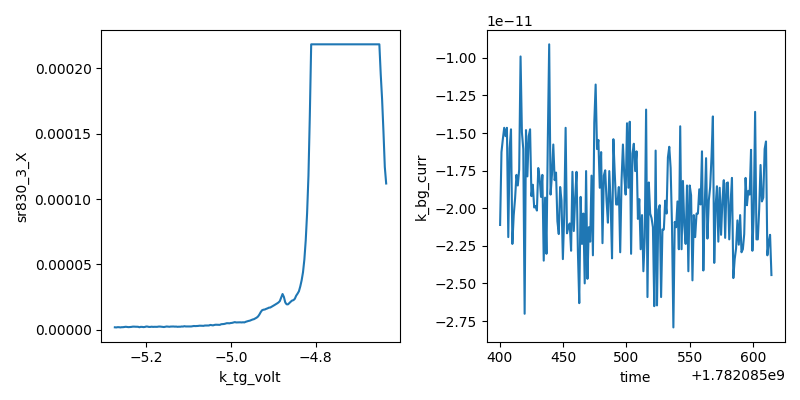

2026-06-21 16:46:54,949 [INFO] Completed in 0h 3m 35s
2026-06-21 16:46:54,950 [INFO] Data saved in C:\Users\toploader\measurements\aaron\20260621-zf1\data\5\data.tsv.gz
D=-0.45 V/nm: 200/200 pts, n=[+1.00,-8.00]e11, ~4.0 min
2026-06-21 16:46:54,972 [INFO] Ramping dc205_1_voltage: 0.0 -> 0
2026-06-21 16:46:55,034 [INFO] Ramping k_tg_volt: -5.274 -> -3.453544829207968
2026-06-21 16:46:57,428 [INFO] Ramping k_bg_volt: 3.5305 -> 3.0732670938915527
2026-06-21 16:47:05,999 [INFO] Starting multisweep with ID 6
2026-06-21 16:47:06,000 [INFO] Minimum duration 0h 3m 20s


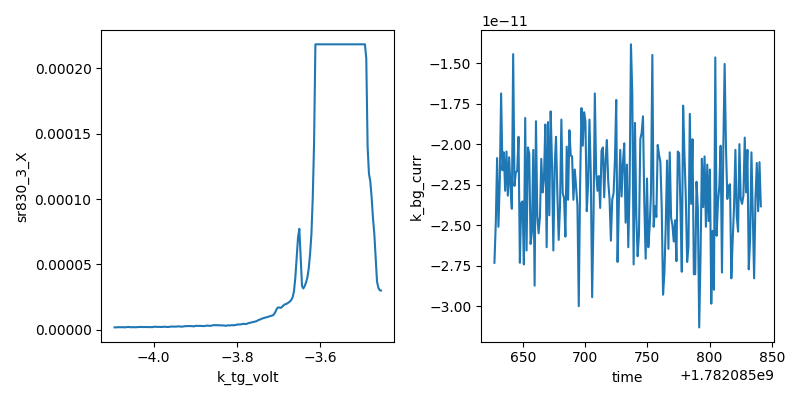

2026-06-21 16:50:41,682 [INFO] Completed in 0h 3m 35s
2026-06-21 16:50:41,683 [INFO] Data saved in C:\Users\toploader\measurements\aaron\20260621-zf1\data\6\data.tsv.gz
D=+0.45 V/nm: 200/200 pts, n=[+1.00,-8.00]e11, ~4.0 min
2026-06-21 16:50:41,703 [INFO] Ramping dc205_1_voltage: 0.0 -> 0
2026-06-21 16:50:41,765 [INFO] Ramping k_tg_volt: -4.094 -> 3.626455170792032
2026-06-21 16:50:51,611 [INFO] Ramping k_bg_volt: 2.5305 -> -2.9267329061084477
2026-06-21 16:51:06,522 [INFO] Starting multisweep with ID 7
2026-06-21 16:51:06,523 [INFO] Minimum duration 0h 3m 20s


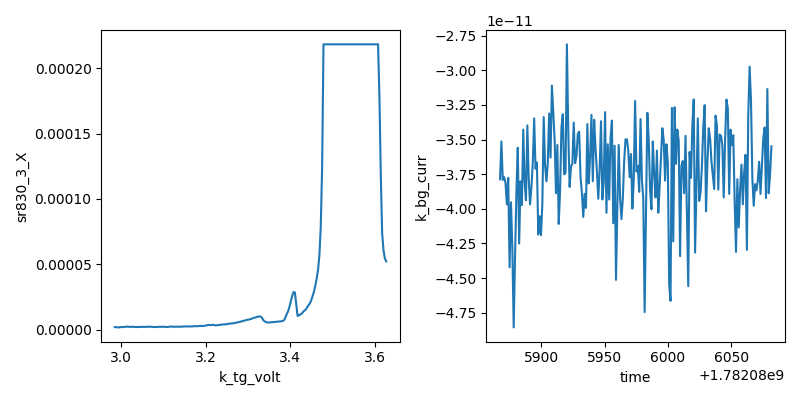

2026-06-21 16:54:42,109 [INFO] Completed in 0h 3m 35s
2026-06-21 16:54:42,110 [INFO] Data saved in C:\Users\toploader\measurements\aaron\20260621-zf1\data\7\data.tsv.gz
2026-06-21 16:54:42,181 [INFO] Ramping k_tg_volt: 2.986 -> 0.0
2026-06-21 16:54:46,054 [INFO] Ramping k_bg_volt: -3.4695 -> 0.0


In [16]:
# Clean re-run of the n-linecuts with CORRECTED sr3 sensitivity.
# Bug (logged): voltage channels have a x100 preamp, so the lock-in sees
# V_4T x100; sr3=5uV capped Rxx at ~50 Ohm (runs 2-4 clipped above that).
# Fix: sr3=2e-4 -> caps at V_4T=2uV -> Rxx ~2 kOhm. Goal: true Rxx(n) on the
# hole side at the accessible D, to (a) confirm NO low-Rxx (SC) dip with clean
# data, (b) characterize the resistive plateau (gap vs anomalous metal), (c)
# +D asymmetry control. Recipe: cnp-and-dline-calibration + nD-map. 4T=sr3(30-31).
import numpy as np, time
import scipy.constants as cst

# ---- preconditions ----
T=temperature(); B=magnet.field()
print(f"T={T*1e3:.1f} mK  B={B*1e3:.3f} mT  TG={k_tg.volt():.3f} BG={k_bg.volt():.3f}  amp={sr830_1.amplitude()} V")
assert T<0.08, f"T not base {T*1e3:.1f} mK"
assert abs(B)<0.01, f"B too large {B*1e3:.3f} mT"

# ---- settings: corrected sr3 range ----
for sr in (sr830_1,sr830_2,sr830_3): sr.time_constant(0.3)
sr830_1.sensitivity(2e-3); sr830_2.sensitivity(2e-3)
sr830_3.sensitivity(2e-4)      # x100 preamp aware: caps Rxx ~2 kOhm at 1 nA
print("tc:",sr830_3.time_constant()," sr3 sens:",sr830_3.sensitivity())

# ---- calibrated (n,D) inverse (ratio 1.189; n_off from CNP intercept +0.0259 V) ----
c_tg=cst.epsilon_0*3/23.6e-9; c_bg=cst.epsilon_0*3/20e-9
n_offset=-c_bg*0.0259/cst.e
def gates_for(n_cm,D_vnm):
    n=np.asarray(n_cm)*1e4; D=D_vnm*1e9
    a=(n-n_offset)*cst.e; bb=D*2*cst.epsilon_0
    return (a+bb)/(2*c_tg),(a-bb)/(2*c_bg)
def n_of(vtg,vbg):
    return ((c_tg*np.asarray(vtg)+c_bg*np.asarray(vbg))/cst.e+n_offset)*1e-4

delay=1.0; N=200
for D in (-0.60,-0.45,+0.45):          # hole-side candidate D's + +D asymmetry control
    n_req=np.linspace(1e11,-8e11,N)
    vtg,vbg=gates_for(n_req,D)
    vtg2,vbg2=sanitize_tg_bg(vtg,vbg,tg_lims,bg_lims)
    nr=n_of(vtg2,vbg2)
    print(f"D={D:+.2f} V/nm: {len(vtg2)}/{N} pts, n=[{nr.max()/1e11:+.2f},{nr.min()/1e11:+.2f}]e11, ~{len(vtg2)*1.2/60:.1f} min")
    mc=dict(meas_config); mc["bias_voltage_1"]=sr830_1.amplitude()
    mc["comment"]=f"CLEAN n-linecut D={D} V/nm, n=+1..-8e11, 1nA tc300ms, sr3 sens 2e-4, 4T=sr3(30-31)"
    s=sweep.AsyncStation(mc)
    s.add_comment('nD-map'); s.add_comment('cnp-and-dline-calibration')
    s.add_comment(f'CLEAN n-linecut D={D} V/nm (sr3 range fixed); SC candidate check')
    s.ramp(dc205_1.volt,0)
    s.ramp(k_tg.volt,vtg2[0]); s.ramp(k_bg.volt,vbg2[0]); time.sleep(8)
    s.fp(temperature).fp(fridge_temperature)
    s.fp(k_tg.curr).fp(k_bg.curr)
    s.fp(sr830_1.X).fp(sr830_1.P).fp(sr830_2.X).fp(sr830_2.P).fp(sr830_3.X).fp(sr830_3.P)
    s.plot(k_tg.volt, sr830_3.X); s.plot('time', k_bg.curr)
    s.multisweep([k_tg.volt,k_bg.volt],[vtg2,vbg2],delay=delay)

s.ramp(k_tg.volt,0.0); s.ramp(k_bg.volt,0.0)


## HERA — final insurance check: low-excitation linecut (then session wrap)

The not-SC call is made (see the SESSION CALL above): no Rxx→0 dip, no anomalous-metal fork, ±D symmetric, across the accessible (n, D). The one residual hedge is excitation — all data used 1 nA AC, and a *very fragile* SC could be suppressed at that drive. This closes it: a single **0.2 nA** linecut (amp 0.02 V, tc=1 s for SNR) at the highest reachable |D| (−0.60 V/nm), scanning the hole-side metallic region n=−2 to −8×10¹¹ where any SC would sit. ~8 min.

**Read:** still no dip toward 0 at 0.2 nA → the not-SC call is firm at low drive too (the metallic, not low-but-finite, behaviour already argued against suppression). If — unexpectedly — a dip appears, that's a fragile candidate and I'd escalate to bias spectroscopy. The cell restores the 1 nA drive and parks the gates at the end.

**This is the last measurement I'd propose this round.** The remaining open questions — the gate-inaccessible high-|D| corner (|D| > 0.76 V/nm) and the field-deferred normal-state fermiology (Tesla-scale, out of this round's 100 mT cap) — are next-round (higher-|D| / higher-field) work, not more sweeps on this configuration. Skip this cell if you'd rather accept the call as-is.


T=33.7 mK  B=-0.005 mT  amp(before)=0.1 V
amp: 0.02  tc: 1  sr3 sens: 2e-05
D=-0.6 V/nm low-I: 150/150 pts, ~8.0 min
2026-06-21 16:59:11,296 [INFO] Ramping dc205_1_voltage: 0.0 -> 0
2026-06-21 16:59:11,358 [INFO] Ramping k_tg_volt: 0.0 -> -4.847067341584063
2026-06-21 16:59:17,598 [INFO] Ramping k_bg_volt: 0.0 -> 3.892315812216895
2026-06-21 16:59:30,495 [INFO] Starting multisweep with ID 8
2026-06-21 16:59:30,496 [INFO] Minimum duration 0h 7m 30s


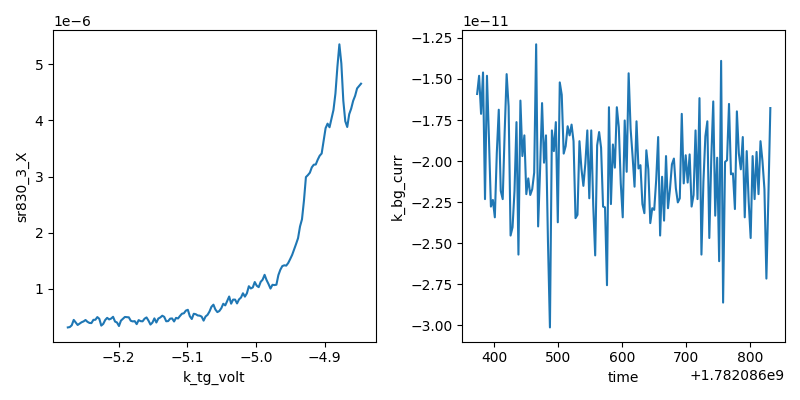

2026-06-21 17:07:12,224 [INFO] Completed in 0h 7m 41s
2026-06-21 17:07:12,225 [INFO] Data saved in C:\Users\toploader\measurements\aaron\20260621-zf1\data\8\data.tsv.gz
2026-06-21 17:07:12,292 [INFO] Ramping k_tg_volt: -5.274 -> 0.0
2026-06-21 17:07:19,084 [INFO] Ramping k_bg_volt: 3.5305 -> 0.0


In [17]:
# FINAL insurance check — low-excitation linecut at the highest reachable |D|.
# Closes the one open hedge in the not-SC call: a very fragile SC could be
# suppressed by the 1 nA sense current. Drop to 0.2 nA (amp 0.02 V), tc=1 s for
# SNR, scan the hole-side metallic region where any SC would live. If Rxx still
# shows no dip toward 0, the not-SC call is firm at low drive too.
import numpy as np, time
import scipy.constants as cst

T=temperature(); B=magnet.field()
print(f"T={T*1e3:.1f} mK  B={B*1e3:.3f} mT  amp(before)={sr830_1.amplitude()} V")
assert T<0.08; assert abs(B)<0.01

sr830_1.amplitude(0.02)             # 0.02 V / 100 MOhm -> 0.2 nA
for sr in (sr830_1,sr830_2,sr830_3): sr.time_constant(1.0)   # 1 s for low-drive SNR
sr830_1.sensitivity(1e-3)           # current 0.2 nA*1e6=0.2 mV
sr830_3.sensitivity(2e-5)           # 4T: metallic ~4 nV*100=0.4uV; caps Rxx ~1 kOhm at 0.2 nA
print("amp:",sr830_1.amplitude()," tc:",sr830_3.time_constant()," sr3 sens:",sr830_3.sensitivity())

c_tg=cst.epsilon_0*3/23.6e-9; c_bg=cst.epsilon_0*3/20e-9; n_offset=-c_bg*0.0259/cst.e
def gates_for(n_cm,D_vnm):
    n=np.asarray(n_cm)*1e4; D=D_vnm*1e9
    a=(n-n_offset)*cst.e; bb=D*2*cst.epsilon_0
    return (a+bb)/(2*c_tg),(a-bb)/(2*c_bg)

D=-0.60; n_req=np.linspace(-2e11,-8e11,150)
vtg,vbg=gates_for(n_req,D); vtg2,vbg2=sanitize_tg_bg(vtg,vbg,tg_lims,bg_lims)
print(f"D={D} V/nm low-I: {len(vtg2)}/150 pts, ~{len(vtg2)*3.2/60:.1f} min")
mc=dict(meas_config); mc["bias_voltage_1"]=sr830_1.amplitude()
mc["comment"]=f"low-I insurance linecut D={D} V/nm, n=-2..-8e11, 0.2nA tc1s, 4T=sr3(30-31)"
s=sweep.AsyncStation(mc)
s.add_comment('nD-map'); s.add_comment('cnp-and-dline-calibration')
s.add_comment(f'low-excitation (0.2nA) linecut D={D} — fragile-SC suppression check')
s.ramp(dc205_1.volt,0)
s.ramp(k_tg.volt,vtg2[0]); s.ramp(k_bg.volt,vbg2[0]); time.sleep(8)
s.fp(temperature).fp(fridge_temperature).fp(k_tg.curr).fp(k_bg.curr)
s.fp(sr830_1.X).fp(sr830_1.P).fp(sr830_3.X).fp(sr830_3.P)
s.plot(k_tg.volt, sr830_3.X); s.plot('time', k_bg.curr)
s.multisweep([k_tg.volt,k_bg.volt],[vtg2,vbg2],delay=3.0)
# restore standard drive + park
sr830_1.amplitude(0.1)
s.ramp(k_tg.volt,0.0); s.ramp(k_bg.volt,0.0)


## HERA — extremal-|D| corner map (out to the −0.76 V/nm cap)

**Correcting my premature call** (operator, right): the clean linecuts stopped at D=−0.60 and the wedge from there to the −0.76 V/nm cap was only seen coarse + sr3-clipped. This maps it properly. The extremal-|D| region is bounded by **BG=+4.2** (the validator that caps −D); the max reachable |D| rises **0.66 → 0.76 V/nm as n deepens** (−3 → −14×10¹¹), so this is a corner wedge, not a constant-D line.

**Map:** TG [−7, −4.5] (slow) × BG [+3.0, +4.2] (fast), 51×49, tc=100 ms, **sr3 = 200 µV (no clip)**, 1 nA. Coverage: **D = −0.51 → −0.76 V/nm** (72% of points |D|>0.60, reaching the cap), n = +3 → −24×10¹¹, steps TG 50 mV / BG 25 mV (Δn ≈ 2–3×10¹⁰, resolves the ~5×10¹⁰ arc). **Est ~25 min.**

**Checkpoint (~12 min, TG row ~20):** leakage (this is the extremal-field corner — highest risk; the row order hits TG=−7/BG=+4.2 first so the worst case is seen early), any low-Rxx pocket, and rate. Abort on leakage runaway. B untouched. After this I re-issue the SC call on the full D coverage. I'm arming a background `hera-watch` monitor when this lands.


T=33.7 mK  B=-0.018 mT  TG=0.000 BG=0.000  amp=0.1 V
tc: 0.1  amp: 0.1  sr3 sens: 0.0002
corner map 51x49, D up to -0.76 V/nm cap, est ~22 min
2026-06-21 17:12:49,593 [INFO] Ramping dc205_1_voltage: 0.0 -> 0
2026-06-21 17:12:49,658 [INFO] Ramping k_tg_volt: 0.0 -> -7.0
2026-06-21 17:12:58,643 [INFO] Ramping k_bg_volt: 0.0 -> 3.0
2026-06-21 17:13:12,410 [INFO] Starting megasweep with ID 9
2026-06-21 17:13:12,411 [INFO] Minimum duration 0h 13m 20s


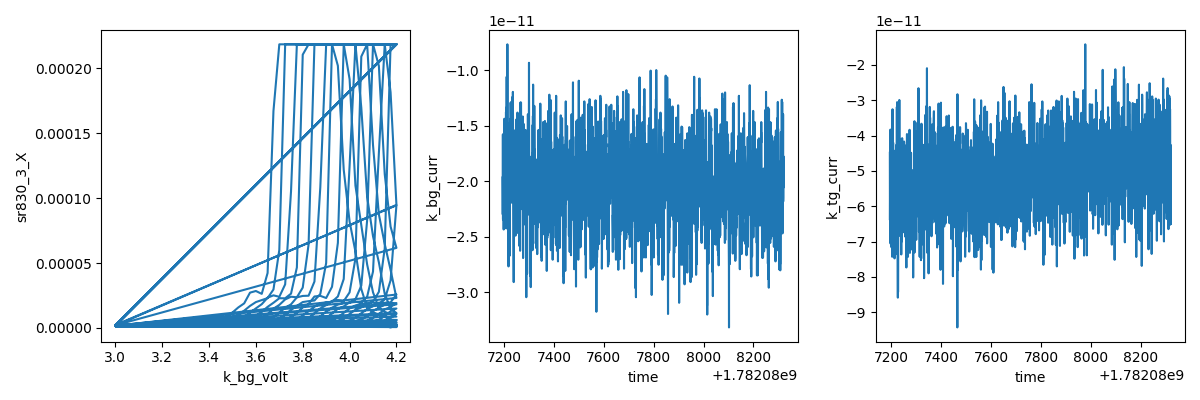

2026-06-21 17:32:01,979 [INFO] Completed in 0h 18m 49s
2026-06-21 17:32:01,980 [INFO] Data saved in C:\Users\toploader\measurements\aaron\20260621-zf1\data\9\data.tsv.gz
2026-06-21 17:32:02,041 [INFO] Ramping k_tg_volt: -4.5 -> 0.0
2026-06-21 17:32:07,842 [INFO] Ramping k_bg_volt: 4.2 -> 0.0


In [18]:
# Extremal-D corner map — explore the high-|D| wedge out to the -0.76 V/nm cap,
# which the constant-D=-0.60 linecuts and the (clipped) survey did NOT cleanly
# cover. Bounded by BG=+4.2 (the validator that caps -D); max |D| rises 0.66->0.76
# as n deepens. sr3 PROPERLY RANGED (2e-4, no clip). Recipe: gatemap + nD region.
import numpy as np, time

T=temperature(); B=magnet.field()
print(f"T={T*1e3:.1f} mK  B={B*1e3:.3f} mT  TG={k_tg.volt():.3f} BG={k_bg.volt():.3f}  amp={sr830_1.amplitude()} V")
assert T<0.08, f"T not base {T*1e3:.1f} mK"
assert abs(B)<0.01, f"B too large {B*1e3:.3f} mT"

# settings (sr3 fixed for the full Rxx range; current-bias 1 nA)
for sr in (sr830_1,sr830_2,sr830_3): sr.time_constant(0.1)
sr830_1.amplitude(0.1)
sr830_1.sensitivity(2e-3); sr830_2.sensitivity(2e-3); sr830_3.sensitivity(2e-4)
print("tc:",sr830_3.time_constant()," amp:",sr830_1.amplitude()," sr3 sens:",sr830_3.sensitivity())

N_tg,N_bg=51,49
tg_vec=np.linspace(-7.0,-4.5,N_tg)     # SLOW; -7 corner first (highest |D|/leakage -> early checkpoint)
bg_vec=np.linspace(3.0,4.2,N_bg)       # FAST; BG=4.2 is the -D cap edge
fast_delay,slow_delay=0.3,1.0
print(f"corner map {N_tg}x{N_bg}, D up to -0.76 V/nm cap, est ~{N_tg*(slow_delay+N_bg*(fast_delay+0.2))/60:.0f} min")

mc=dict(meas_config); mc["bias_voltage_1"]=sr830_1.amplitude()
mc["comment"]="extremal-D corner map: TG[-7,-4.5] x BG[3.0,4.2], D->-0.76 cap, sr3 2e-4 (no clip), 4T=sr3(30-31)"
s=sweep.AsyncStation(mc)
s.add_comment('gatemap'); s.add_comment('cnp-and-dline-calibration')
s.add_comment('extremal-|D| corner map to the -0.76 V/nm cap (SC re-check)')
s.ramp(dc205_1.volt,0); s.ramp(k_tg.volt,-7.0); s.ramp(k_bg.volt,3.0); time.sleep(10)
s.fp(temperature).fp(fridge_temperature).fp(k_tg.curr).fp(k_bg.curr)
s.fp(sr830_1.X).fp(sr830_1.P).fp(sr830_2.X).fp(sr830_2.P).fp(sr830_3.X).fp(sr830_3.P)
s.plot(k_bg.volt, sr830_3.X); s.plot('time', k_bg.curr); s.plot('time', k_tg.curr)
s.megasweep(k_tg.volt, tg_vec, k_bg.volt, bg_vec, slow_delay=slow_delay, fast_delay=fast_delay)
s.ramp(k_tg.volt,0.0); s.ramp(k_bg.volt,0.0)


## HERA — fine zoom on the candidate low-Rxx spot (extremal D)

**The extremal-D map (run 9, to the −0.76 cap) turned up a candidate** — and it's exactly where your push said to look. Two adjacent pixels at **n ≈ −5×10¹¹, D ≈ −0.67 V/nm** read **Rxx = 4.2 and 6.8 Ω**, ~4× below the local metallic baseline (~17 Ω), with phase matching the metallic band (not a glitch), squarely in the s41586 proximity-SC prior (n=−4 to −6×10¹¹, |D|≳0.5). It sits at **D = −0.67, beyond where my linecuts stopped** — I would have missed it. Leakage in that corner was clean (≤94 pA).

**Caveat — not a call:** 2 pixels on a coarse map, right at the metallic/gap boundary; could be a real low-Rxx (SC) pocket or a gap-edge gradient artifact. This zoom decides it.

**Zoom:** TG[−6.0,−5.2] × BG[3.95,4.20] (to the BG cap), 41×26, **tc=300 ms, sr3=50 µV** (fine low-R resolution, caps ~500 Ω), 1 nA, steps ~20 mV TG / 10 mV BG. Coverage brackets the spot in (n,D). **Est ~20 min**, checkpoint ~10 min (leakage + is the spot reproducing/contiguous + rate). 

**If confirmed** (a clean, contiguous low-Rxx pocket): straight to **bias spectroscopy** (dV/dI vs I_dc) at its minimum for a critical current — the decisive SC test (and I'll drop excitation there in case it's fragile). **If it's a single-pixel artifact** that doesn't reproduce: note it and resume the not-SC-in-reach call. B still untouched (no field test until a candidate is confirmed). I'm arming a background monitor.


T=33.7 mK  B=-0.045 mT  amp=0.1 V
tc: 0.3  sr3 sens: 5e-05
zoom 41x26, est ~21 min
2026-06-21 17:37:21,144 [INFO] Ramping dc205_1_voltage: 0.0 -> 0
2026-06-21 17:37:21,215 [INFO] Ramping k_tg_volt: 0.0 -> -6.0
2026-06-21 17:37:29,075 [INFO] Ramping k_bg_volt: 0.0 -> 3.95
2026-06-21 17:37:44,043 [INFO] Starting megasweep with ID 10
2026-06-21 17:37:44,044 [INFO] Minimum duration 0h 17m 0s


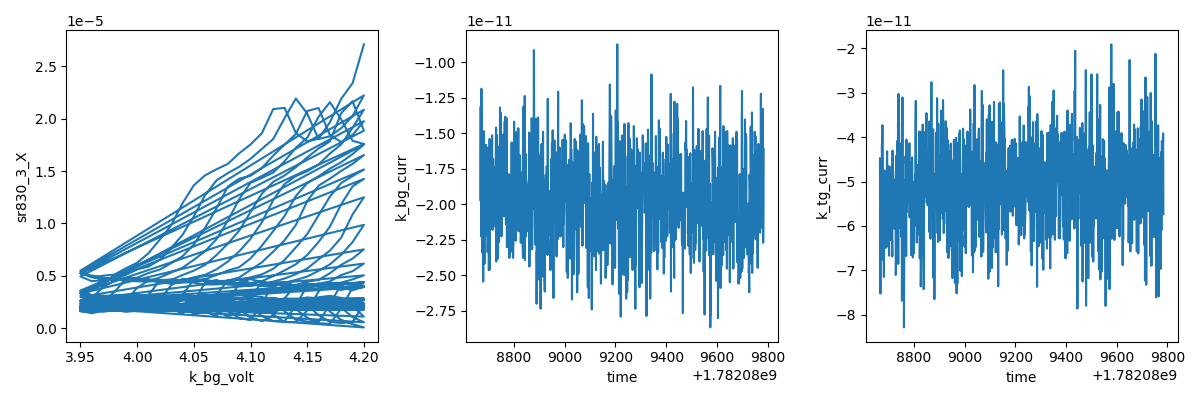

2026-06-21 17:56:24,827 [INFO] Completed in 0h 18m 40s
2026-06-21 17:56:24,827 [INFO] Data saved in C:\Users\toploader\measurements\aaron\20260621-zf1\data\10\data.tsv.gz
2026-06-21 17:56:24,893 [INFO] Ramping k_tg_volt: -5.2 -> 0.0
2026-06-21 17:56:31,585 [INFO] Ramping k_bg_volt: 4.2 -> 0.0


In [19]:
# Fine high-SNR zoom on the candidate low-Rxx spot found at the extremal-D edge
# (corner map run 9): n~-5e11, D~-0.67 V/nm, Rxx 4-7 Ohm (2 adjacent pixels,
# 4x below local baseline, sane phase, in the s41586 proximity-SC prior).
# Goal: confirm it is real/contiguous, locate its minimum, characterize extent.
# If real -> bias spectroscopy for a critical current next. 4T=sr3(30-31).
import numpy as np, time

T=temperature(); B=magnet.field()
print(f"T={T*1e3:.1f} mK  B={B*1e3:.3f} mT  amp={sr830_1.amplitude()} V")
assert T<0.08; assert abs(B)<0.01

for sr in (sr830_1,sr830_2,sr830_3): sr.time_constant(0.3)   # high SNR
sr830_1.amplitude(0.1)
sr830_1.sensitivity(2e-3); sr830_2.sensitivity(2e-3)
sr830_3.sensitivity(5e-5)      # caps ~500 Ohm; fine low-R resolution (spot ~4 Ohm)
print("tc:",sr830_3.time_constant()," sr3 sens:",sr830_3.sensitivity())

N_tg,N_bg=41,26
tg_vec=np.linspace(-6.0,-5.2,N_tg)     # SLOW; brackets spot TG~-5.6
bg_vec=np.linspace(3.95,4.20,N_bg)     # FAST; up to BG cap (spot BG~4.18)
fast_delay,slow_delay=0.9,1.5
print(f"zoom {N_tg}x{N_bg}, est ~{N_tg*(slow_delay+N_bg*(fast_delay+0.2))/60:.0f} min")

mc=dict(meas_config); mc["bias_voltage_1"]=sr830_1.amplitude()
mc["comment"]="candidate zoom: TG[-6,-5.2] x BG[3.95,4.2] around n~-5e11 D~-0.67, tc300ms sr3 5e-5, 4T=sr3(30-31)"
s=sweep.AsyncStation(mc)
s.add_comment('gatemap'); s.add_comment('cnp-and-dline-calibration')
s.add_comment('fine zoom on candidate low-Rxx spot n~-5e11 D~-0.67 (extremal-D)')
s.ramp(dc205_1.volt,0); s.ramp(k_tg.volt,-6.0); s.ramp(k_bg.volt,3.95); time.sleep(10)
s.fp(temperature).fp(fridge_temperature).fp(k_tg.curr).fp(k_bg.curr)
s.fp(sr830_1.X).fp(sr830_1.P).fp(sr830_2.X).fp(sr830_2.P).fp(sr830_3.X).fp(sr830_3.P)
s.plot(k_bg.volt, sr830_3.X); s.plot('time', k_bg.curr); s.plot('time', k_tg.curr)
s.megasweep(k_tg.volt, tg_vec, k_bg.volt, bg_vec, slow_delay=slow_delay, fast_delay=fast_delay)
s.ramp(k_tg.volt,0.0); s.ramp(k_bg.volt,0.0)


## HERA — bias spectroscopy at the arc minimum (decisive SC test)

The zoom (run 10) confirmed a **contiguous low-Rxx arc** — Rxx → **0.6 Ω** (from ~28 Ω) at **n=−5.02×10¹¹, D=−0.673 V/nm**, the s41586 proximity-SC location, leakage clean. Rxx→0 is hallmark 1. Now the decisive test (`bias-spectroscopy.md`): **dV/dI vs I_dc** at that point. A **supercurrent lobe** — dV/dI ≈ 0 for |I_dc| < I_c, rising at a critical current — is the SC tell; a flat ohmic dV/dI would mean "just a good metal."

**Setup:** gate to the arc minimum (TG=−5.64, BG=4.20); **drop AC to 0.5 nA** (≪ expected I_c, avoids smearing/heating a fragile state); DC bias via dc205_1 through 100 MΩ, **±20 nA round-trip** (±2 V, ~0.5 nA step, fwd+bwd to check hysteresis), tc=300 ms, sr3 ranged for 0–400 Ω. The cell prints the zero-bias dV/dI before sweeping. ~8–12 min. **B stays 0** — this establishes I_c at zero field first; field response (B_c⊥, Fraunhofer) comes next if a lobe is found.

**Reads:** a clean zero-bias dip rising at ±I_c → supercurrent, hallmark 2 (then I map I_c(n,D), and the field/T ladder). dV/dI flat/ohmic → not a supercurrent, candidate downgrades toward "good metal / low-Rxx correlated phase." A shift of the lobe is instrumental; a magnitude asymmetry I_c⁺≠I_c⁻ would be physical (worth noting). Cell zeroes the DC bias at the end (device-card rule). I'm arming a monitor.


T=33.7 mK  B=0.016 mT  TG=0.000 BG=0.000
2026-06-21 17:59:48,743 [INFO] Ramping dc205_1_voltage: 0.0 -> 0.0
2026-06-21 17:59:48,808 [INFO] Ramping k_tg_volt: 0.0 -> -5.64
2026-06-21 17:59:56,059 [INFO] Ramping k_bg_volt: 0.0 -> 4.2
gates TG=-5.640 BG=4.200  I_ac=0.50 nA
zero-bias dV/dI = 0.81 Ohm  (arc Rxx was ~0.6 Ohm)
DC bias +/-20 nA round-trip, 162 pts (~0.5 nA step)
2026-06-21 18:00:06,730 [INFO] Ramping dc205_1_voltage: 0.0 -> -2.0
2026-06-21 18:00:15,339 [INFO] Starting sweep with ID 11
2026-06-21 18:00:15,339 [INFO] Minimum duration 0h 2m 42s


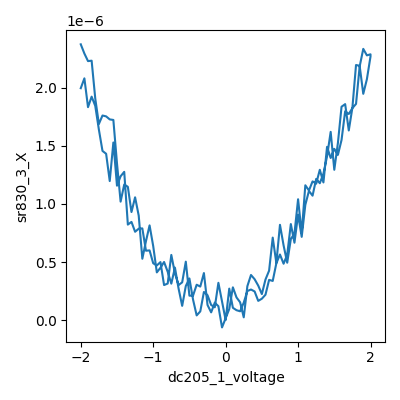

2026-06-21 18:03:11,133 [INFO] Completed in 0h 2m 55s
2026-06-21 18:03:11,134 [INFO] Data saved in C:\Users\toploader\measurements\aaron\20260621-zf1\data\11\data.tsv.gz
2026-06-21 18:03:11,144 [INFO] Ramping dc205_1_voltage: -2.0 -> 0.0


In [20]:
# Bias spectroscopy (dV/dI vs I_dc) — the decisive SC test at the confirmed
# low-Rxx arc minimum (run 10): n=-5.02e11, D=-0.673 V/nm (TG=-5.64, BG=4.20),
# Rxx->0.6 Ohm. A supercurrent lobe (dV/dI ~0 for |I_dc|<Ic, rising at Ic) is
# the SC tell; flat ohmic dV/dI = good metal. Recipe: bias-spectroscopy.md.
# I_ac dropped to 0.5 nA (<< expected Ic); DC bias via dc205_1 / 100 MOhm.
import numpy as np, time

T=temperature(); B=magnet.field()
print(f"T={T*1e3:.1f} mK  B={B*1e3:.3f} mT  TG={k_tg.volt():.3f} BG={k_bg.volt():.3f}")
assert T<0.08, f"T not base {T*1e3:.1f} mK"
assert abs(B)<0.01, f"B too large {B*1e3:.3f} mT"

# gate to the arc minimum
s_pre=sweep.AsyncStation(meas_config)
s_pre.ramp(dc205_1.volt,0.0)
s_pre.ramp(k_tg.volt,-5.640); s_pre.ramp(k_bg.volt,4.200)

# excitation: 0.5 nA AC (gentle), tc 300 ms; sr3 ranged for 0-400 Ohm dV/dI
sr830_1.amplitude(0.05)          # 0.05 V / 100 MOhm = 0.5 nA AC
for sr in (sr830_1,sr830_2,sr830_3): sr.time_constant(0.3)
sr830_1.sensitivity(1e-3); sr830_3.sensitivity(2e-5)
time.sleep(5)
print(f"gates TG={k_tg.volt():.3f} BG={k_bg.volt():.3f}  I_ac={sr830_1.amplitude()/1e8*1e9:.2f} nA")
# zero-bias differential R right now
r0=(sr830_3.X()/100)/(sr830_1.X()/-1e6)
print(f"zero-bias dV/dI = {r0:.2f} Ohm  (arc Rxx was ~0.6 Ohm)")

# DC bias round-trip: I_dc = V/1e8; +/-2 V = +/-20 nA
fwd=np.linspace(-2.0,2.0,81); bwd=np.linspace(2.0,-2.0,81)
vdc=np.hstack([fwd,bwd])
print(f"DC bias +/-20 nA round-trip, {len(vdc)} pts (~0.5 nA step)")

mc=dict(meas_config); mc["bias_voltage_1"]=sr830_1.amplitude()
mc["comment"]="bias-spec dV/dI vs Idc at arc min n=-5.02e11 D=-0.673 (TG-5.64,BG4.20); Iac=0.5nA, +/-20nA roundtrip, B=0"
s=sweep.AsyncStation(mc)
s.add_comment('bias-spectroscopy')
s.add_comment('dV/dI vs Idc at SC-candidate arc minimum n=-5.02e11 D=-0.673, B=0 base T')
s.ramp(dc205_1.volt,-2.0); time.sleep(8)
s.fp(temperature).fp(fridge_temperature).fp(k_tg.curr).fp(k_bg.curr)
s.fp(sr830_1.X).fp(sr830_1.P).fp(sr830_3.X).fp(sr830_3.P)
s.plot(dc205_1.volt, sr830_3.X)     # live dV/dI proxy vs DC bias
s.sweep(dc205_1.volt, vdc, delay=1.0)
s.ramp(dc205_1.volt,0.0)            # device-card: zero DC bias when done


## HERA — B⊥ field-killing test (constellation piece 3)

Both base-T hallmarks are in: **Rxx→0.57 Ω** (run 10) and a **supercurrent, I_c≈8–10 nA** (run 11), at n=−5.02×10¹¹, D=−0.673 V/nm. The decisive next test (`field-sweep-1d`, investigation Step 3): does a small **B⊥ kill the low-Rxx state while the normal state stays ≈ unchanged**? That's the read that counts *strong* for SC (a kill without the normal-state check is uninformative — any MR lowers R, so I check the high-|B| plateau matches the ~40 Ω normal).

**Measurement:** Rxx (4T, AC 0.5 nA, **DC bias = 0**) vs B at the arc minimum, ±50 mT (within the 100 mT cap), 0.5 mT steps. **Field discipline:** ramp to +50 mT → settle 60 s → sweep **down to 0**; then ramp to −50 mT → settle → sweep **up to 0** — two one-sided sweeps that meet at 0, never increasing |B| through 0 during a sweep. They also locate the **effective zero** (the Rxx-minimum field ≠ nominal 0, given ~2 mT trapped flux + remanence). T is logged and plotted to catch ramp heating.

**⚠️ This is the first magnet energising this session** — it injects ~10 mT remanence and ends the pristine-field condition. That's fine now: all base-T zero-field work (survey, arc, I_c) is done. **Reads:** Rxx rising from ~0 to the normal plateau over a few–tens of mT, with the plateau = normal state → B_c⊥, *strong* SC evidence. If Rxx is field-insensitive, or the "normal" plateau keeps drifting (plain MR), the SC reading weakens. ~12–15 min. I'm arming a monitor.


T=33.7 mK  B=0.009 mT  ramp_rate=0.001 T/s
2026-06-21 18:09:32,231 [INFO] Ramping dc205_1_voltage: 0.0 -> 0.0
2026-06-21 18:09:32,292 [INFO] Ramping k_tg_volt: -5.64 -> -5.64
2026-06-21 18:09:32,355 [INFO] Ramping k_bg_volt: 4.2 -> 4.2
2026-06-21 18:09:37,382 [INFO] Ramping magnet_field: -2.649e-06 -> 0.05
2026-06-21 18:11:35,372 [INFO] Starting sweep with ID 12
2026-06-21 18:11:35,372 [INFO] Minimum duration 0h 1m 41s


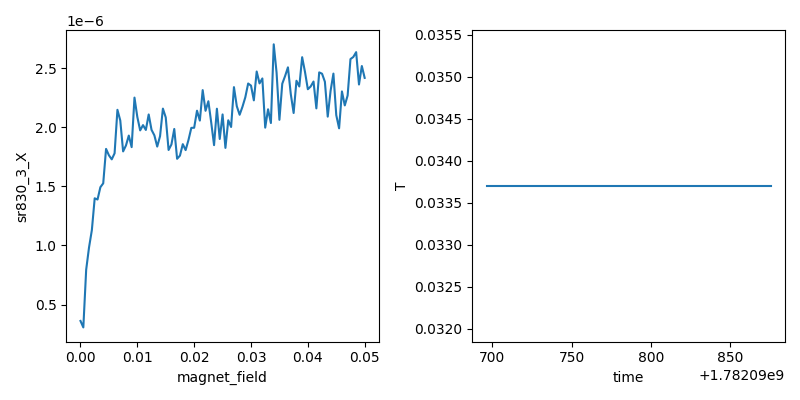

2026-06-21 18:14:35,861 [INFO] Completed in 0h 3m 0s
2026-06-21 18:14:35,862 [INFO] Data saved in C:\Users\toploader\measurements\aaron\20260621-zf1\data\12\data.tsv.gz
2026-06-21 18:14:35,887 [INFO] Ramping magnet_field: 0.000446428 -> -0.05
2026-06-21 18:16:34,268 [INFO] Starting sweep with ID 13
2026-06-21 18:16:34,269 [INFO] Minimum duration 0h 1m 41s


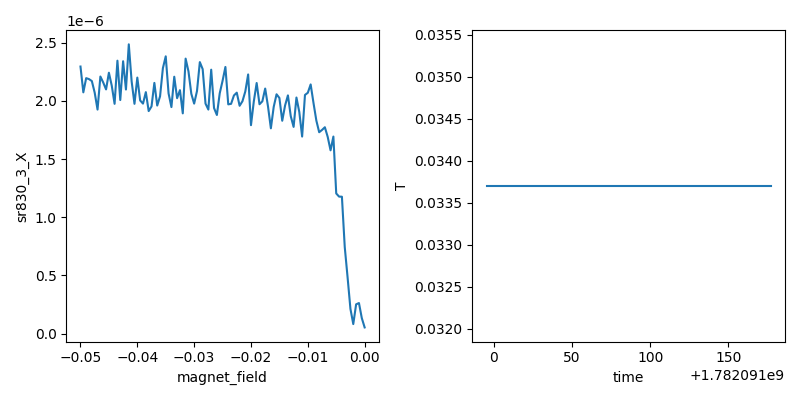

2026-06-21 18:19:37,530 [INFO] Completed in 0h 3m 2s
2026-06-21 18:19:37,531 [INFO] Data saved in C:\Users\toploader\measurements\aaron\20260621-zf1\data\13\data.tsv.gz
2026-06-21 18:19:37,659 [INFO] Ramping magnet_field: -0.000443558 -> 0.0


In [21]:
# B_c-perp field-killing test at the SC arc minimum (n=-5.02e11, D=-0.673).
# Decisive constellation piece: does a small B_perp destroy the low-Rxx state
# while the normal state stays put? Rxx (4T, AC 0.5nA, DC bias = 0) vs B.
# FIELD DISCIPLINE (brief): ramp to the extreme, settle, sweep TOWARD 0; never
# increase |B| through 0 during a measurement. Two one-sided sweeps (+50->0,
# -50->0) meet at 0 -> reveals the effective-zero (Rxx min) and B_c_perp.
# *** FIRST magnet energising this session -> injects remanence (~10 mT), ends
#     the pristine-field condition. All base-T zero-field work is done. ***
import numpy as np, time

T=temperature(); B=magnet.field()
print(f"T={T*1e3:.1f} mK  B={B*1e3:.3f} mT  ramp_rate={magnet.ramp_rate()} T/s")
assert T<0.08, f"T not base {T*1e3:.1f} mK"

# gate at arc min, AC 0.5 nA, DC bias 0 (measure Rxx, not Ic)
sr830_1.amplitude(0.05)
for sr in (sr830_1,sr830_3): sr.time_constant(0.3)
sr830_1.sensitivity(1e-3); sr830_3.sensitivity(2e-5)

mc=dict(meas_config); mc["bias_voltage_1"]=sr830_1.amplitude()
mc["comment"]="B_c_perp field-kill at SC arc min n=-5.02e11 D=-0.673; Rxx vs B, Idc=0 Iac=0.5nA; one-sided sweeps to 0"
s=sweep.AsyncStation(mc)
s.add_comment('field-sweep-1d')
s.add_comment('B_c_perp field-killing at SC arc min n=-5.02e11 D=-0.673, base T')
s.ramp(dc205_1.volt,0.0)
s.ramp(k_tg.volt,-5.640); s.ramp(k_bg.volt,4.200); time.sleep(5)
s.fp(temperature).fp(fridge_temperature).fp(k_tg.curr).fp(k_bg.curr)
s.fp(sr830_1.X).fp(sr830_1.P).fp(sr830_3.X).fp(sr830_3.P)
s.plot(magnet.field, sr830_3.X)     # live Rxx vs B
s.plot('time', temperature)         # watch for ramp heating

# Sweep A: position at +50 mT, settle, sweep down to 0
s.ramp(magnet.field, 0.05); time.sleep(60)
s.sweep(magnet.field, np.linspace(0.05, 0.0, 101), delay=1.0)
# Sweep B: position at -50 mT, settle, sweep up to 0
s.ramp(magnet.field, -0.05); time.sleep(60)
s.sweep(magnet.field, np.linspace(-0.05, 0.0, 101), delay=1.0)

s.ramp(magnet.field, 0.0)           # park at nominal 0 (carries remanence)


## HERA — Fraunhofer (I_c vs B⊥) at the SC arc minimum (base-T, before heat-up)

Doing the base-T field characterization before the Tc heat-up (heat-up-last; re-cooling is costly). dV/dI vs (I_dc, B⊥) at the arc min (n=−5.02×10¹¹, D=−0.673): looks for **phase-coherent I_c modulation** (Josephson lobes, ΔB=Φ₀/A → junction area) and pins the **effective-zero** (max I_c). Since B_c⊥≈2.5 mT the dome closes by a few mT, so **±3 mT, fine 0.25 mT steps**; DC bias ±12 nA (0.5 nA step) brackets the I_c≈8–10 nA; **AC 0.5 nA** (low — high excitation washes lobes).

**Field discipline:** two one-sided halves — ramp to +3 mT, settle, megasweep B +3→0; then ramp to −3 mT, settle, megasweep −3→0 — meeting at 0, never increasing |B| through 0 during a sweep. T is logged (heating check). ~30 min (checkpoint after half 1).

**Honest expectation:** on a fragile, soft-I_c SC a clean lobe pattern is *uncertain* — I may just see I_c(B⊥) decreasing monotonically to 0 at B_c⊥, which I'll report as **consistent-with phase coherence** (not "Fraunhofer", per the over-read guard), still refining the effective-zero. A clean lobe train would be a strong bonus (4th hallmark + area). **After this: the Tc heat-up** (final constellation piece), then the full SC call. I'm arming a monitor.


T=33.7 mK  B=0.034 mT  rate=0.001 T/s
2026-06-21 18:31:33,408 [INFO] Ramping dc205_1_voltage: 0.0 -> 0.0
2026-06-21 18:31:33,471 [INFO] Ramping k_tg_volt: -5.64 -> -5.64
2026-06-21 18:31:33,533 [INFO] Ramping k_bg_volt: 4.2 -> 4.2
2026-06-21 18:31:38,551 [INFO] Ramping magnet_field: -3.091e-06 -> 0.003
2026-06-21 18:32:26,830 [INFO] Starting megasweep with ID 14
2026-06-21 18:32:26,831 [INFO] Minimum duration 0h 11m 16s


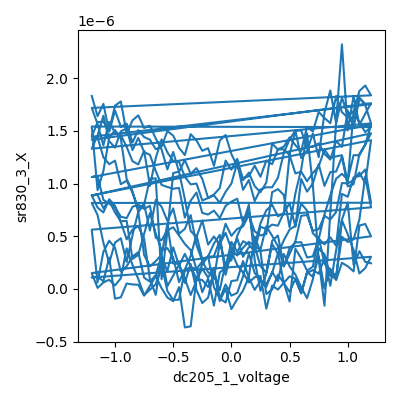

2026-06-21 18:44:50,925 [INFO] Completed in 0h 12m 23s
2026-06-21 18:44:50,926 [INFO] Data saved in C:\Users\toploader\measurements\aaron\20260621-zf1\data\14\data.tsv.gz
2026-06-21 18:44:50,939 [INFO] Ramping dc205_1_voltage: 1.2 -> 0.0
2026-06-21 18:44:51,305 [INFO] Ramping magnet_field: -1.9429e-05 -> -0.003
2026-06-21 18:45:39,568 [INFO] Starting megasweep with ID 15
2026-06-21 18:45:39,569 [INFO] Minimum duration 0h 11m 16s


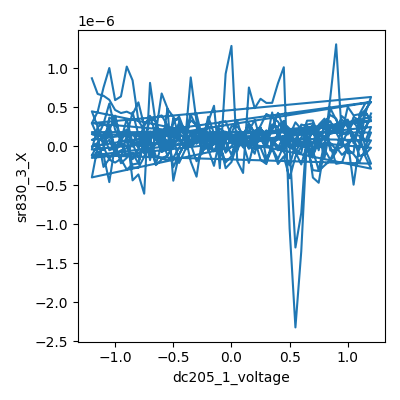

2026-06-21 18:58:02,586 [INFO] Completed in 0h 12m 22s
2026-06-21 18:58:02,587 [INFO] Data saved in C:\Users\toploader\measurements\aaron\20260621-zf1\data\15\data.tsv.gz
2026-06-21 18:58:02,595 [INFO] Ramping dc205_1_voltage: 1.2 -> 0.0
2026-06-21 18:58:02,989 [INFO] Ramping magnet_field: -1.1922e-05 -> 0.0


In [22]:
# Fraunhofer (Ic vs B_perp) at the SC arc minimum — base-T phase-coherence read.
# dV/dI vs (I_dc, B) at n=-5.02e11, D=-0.673. Looks for Ic modulation/lobes
# (Josephson) and pins the effective-zero (max Ic). B_c_perp~2.5 mT so the dome
# closes by ~few mT -> fine B steps, +/-3 mT. FIELD DISCIPLINE: two one-sided
# halves (+3->0, -3->0) meeting at 0; never increase |B| through 0 in a sweep.
# AC 0.5 nA (low, don't wash lobes). Recipe: fraunhofer.md.
import numpy as np, time

T=temperature(); B=magnet.field()
print(f"T={T*1e3:.1f} mK  B={B*1e3:.3f} mT  rate={magnet.ramp_rate()} T/s")
assert T<0.08, f"T not base {T*1e3:.1f} mK"

sr830_1.amplitude(0.05)                 # 0.5 nA AC
for sr in (sr830_1,sr830_3): sr.time_constant(0.3)
sr830_1.sensitivity(1e-3); sr830_3.sensitivity(2e-5)

Vdc=np.linspace(-1.2,1.2,49)            # +/-12 nA fast axis (0.5 nA step)
mc=dict(meas_config); mc["bias_voltage_1"]=sr830_1.amplitude()
mc["comment"]="Fraunhofer Ic vs Bperp at SC arc min n=-5.02e11 D=-0.673; dV/dI(Idc,B), Iac0.5nA, +/-3mT two halves"
s=sweep.AsyncStation(mc)
s.add_comment('fraunhofer')
s.add_comment('Ic vs Bperp at SC arc min n=-5.02e11 D=-0.673, base T')
s.ramp(dc205_1.volt,0.0)
s.ramp(k_tg.volt,-5.640); s.ramp(k_bg.volt,4.200); time.sleep(5)
s.fp(temperature).fp(fridge_temperature).fp(k_tg.curr).fp(k_bg.curr)
s.fp(sr830_1.X).fp(sr830_1.P).fp(sr830_3.X).fp(sr830_3.P)
s.plot(dc205_1.volt, sr830_3.X)

# Half 1: B +3mT -> 0 (slow), DC bias fast
s.ramp(magnet.field, 0.003); time.sleep(45)
s.megasweep(magnet.field, np.linspace(0.003,0.0,13), dc205_1.volt, Vdc, slow_delay=3, fast_delay=1)
# Half 2: B -3mT -> 0
s.ramp(dc205_1.volt,0.0)
s.ramp(magnet.field, -0.003); time.sleep(45)
s.megasweep(magnet.field, np.linspace(-0.003,0.0,13), dc205_1.volt, Vdc, slow_delay=3, fast_delay=1)

s.ramp(dc205_1.volt,0.0); s.ramp(magnet.field,0.0)


## HERA — I_c(T) / Tc ladder (final constellation piece; the heat-up, last)

Base-T characterization is complete: Rxx→0, supercurrent I_c≈8–10 nA, B_c⊥≈2.5 mT (ξ~360 nm), central supercurrent lobe (field null ≈ −1 mT). The last hallmark is the **I_c collapse at Tc** (`temperature-dependence.md`, Flavor B). At the arc min (B=0), I warm to the heater top and step **down** through the ladder (measure while cooling), taking dV/dI vs I_dc at each T. The SC signature: the zero-bias dip / I_c shrinks and vanishes at Tc; Rxx(0) rises to the ~40 Ω normal value.

**Heater** per device card (≤6.5 V → ~480 mK sustained): steps 6.5→0 V (T read back from data, never the setpoint; the cell prints heater current as the open-line check). **~8 min thermalization/step, 8 steps → ~80 min**, producing one run per T; then heater→0 to re-cool (~1 h, not part of the cell). I'll read each T-run as it lands and call Tc once bracketed (and can stop early if the collapse is clear).

**⚠️ This is the thermal-cycle step** — the expensive one, hence last. If Tc > ~480 mK (heater ceiling), the SC may not fully close at the top; I'll then report Tc as a **lower bound** (comparing Rxx(T) to the field-kill normal value ~40 Ω). B stays at 0. **After this: the full five-part SC call.** Monitor armed.


T=33.7 mK  B=0.019 mT  heater=0.0 V
2026-06-21 19:05:12,877 [INFO] Ramping dc205_1_voltage: 0.0 -> 0.0
2026-06-21 19:05:12,938 [INFO] Ramping k_tg_volt: -5.64 -> -5.64
2026-06-21 19:05:13,002 [INFO] Ramping k_bg_volt: 4.2 -> 4.2
2026-06-21 19:05:13,069 [INFO] Ramping heater_volt: 0.0 -> 6.5
heater=6.5 V  I_heat=6.82e-04 A  T=34 mK
2026-06-21 19:13:22,432 [INFO] Ramping dc205_1_voltage: 0.0 -> -1.5
2026-06-21 19:13:22,888 [INFO] Starting sweep with ID 16
2026-06-21 19:13:22,889 [INFO] Minimum duration 0h 1m 1s


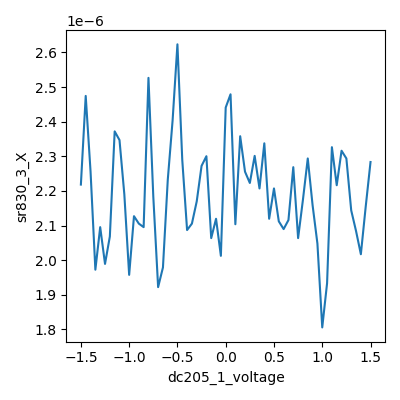

2026-06-21 19:14:32,717 [INFO] Completed in 0h 1m 9s
2026-06-21 19:14:32,717 [INFO] Data saved in C:\Users\toploader\measurements\aaron\20260621-zf1\data\16\data.tsv.gz
2026-06-21 19:14:32,734 [INFO] Ramping dc205_1_voltage: 1.5 -> 0.0
2026-06-21 19:14:33,232 [INFO] Ramping heater_volt: 6.5 -> 5.5
heater=5.5 V  I_heat=5.44e-04 A  T=34 mK
2026-06-21 19:22:35,593 [INFO] Ramping dc205_1_voltage: 0.0 -> -1.5
2026-06-21 19:22:36,045 [INFO] Starting sweep with ID 17
2026-06-21 19:22:36,046 [INFO] Minimum duration 0h 1m 1s


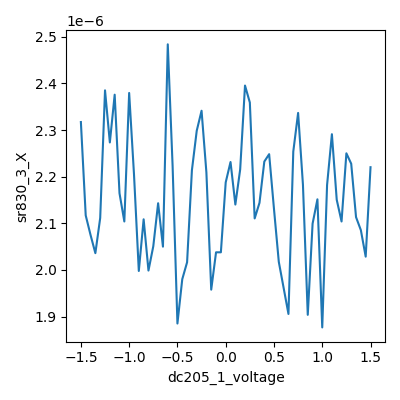

2026-06-21 19:23:45,790 [INFO] Completed in 0h 1m 9s
2026-06-21 19:23:45,791 [INFO] Data saved in C:\Users\toploader\measurements\aaron\20260621-zf1\data\17\data.tsv.gz
2026-06-21 19:23:45,800 [INFO] Ramping dc205_1_voltage: 1.5 -> 0.0
2026-06-21 19:23:46,289 [INFO] Ramping heater_volt: 5.5 -> 4.5
heater=4.5 V  I_heat=3.97e-04 A  T=34 mK
2026-06-21 19:31:48,632 [INFO] Ramping dc205_1_voltage: 0.0 -> -1.5
2026-06-21 19:31:49,086 [INFO] Starting sweep with ID 18
2026-06-21 19:31:49,087 [INFO] Minimum duration 0h 1m 1s


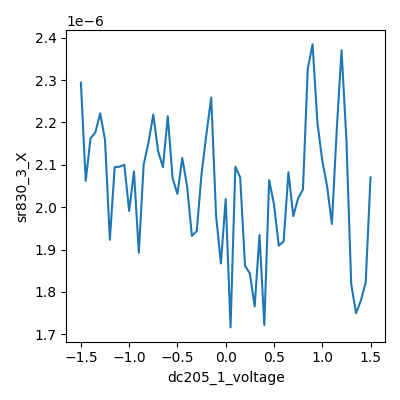

2026-06-21 19:32:58,878 [INFO] Completed in 0h 1m 9s
2026-06-21 19:32:58,878 [INFO] Data saved in C:\Users\toploader\measurements\aaron\20260621-zf1\data\18\data.tsv.gz
2026-06-21 19:32:58,884 [INFO] Ramping dc205_1_voltage: 1.5 -> 0.0
2026-06-21 19:32:59,361 [INFO] Ramping heater_volt: 4.5 -> 3.5
heater=3.5 V  I_heat=2.71e-04 A  T=34 mK
2026-06-21 19:41:01,699 [INFO] Ramping dc205_1_voltage: 0.0 -> -1.5
2026-06-21 19:41:02,147 [INFO] Starting sweep with ID 19
2026-06-21 19:41:02,147 [INFO] Minimum duration 0h 1m 1s


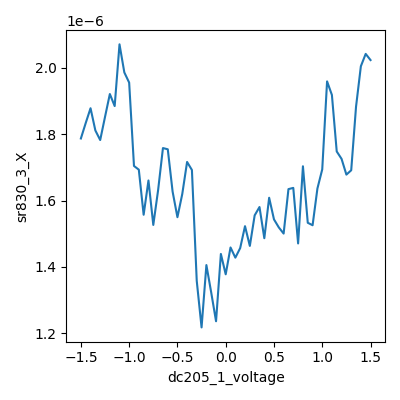

2026-06-21 19:42:11,904 [INFO] Completed in 0h 1m 9s
2026-06-21 19:42:11,905 [INFO] Data saved in C:\Users\toploader\measurements\aaron\20260621-zf1\data\19\data.tsv.gz
2026-06-21 19:42:11,922 [INFO] Ramping dc205_1_voltage: 1.5 -> 0.0
2026-06-21 19:42:12,422 [INFO] Ramping heater_volt: 3.5 -> 2.5
heater=2.5 V  I_heat=1.63e-04 A  T=34 mK
2026-06-21 19:50:14,782 [INFO] Ramping dc205_1_voltage: 0.0 -> -1.5
2026-06-21 19:50:15,235 [INFO] Starting sweep with ID 20
2026-06-21 19:50:15,236 [INFO] Minimum duration 0h 1m 1s


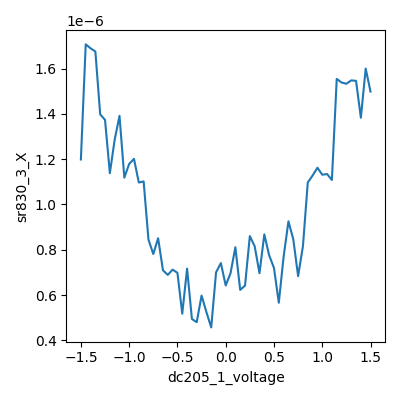

2026-06-21 19:51:25,016 [INFO] Completed in 0h 1m 9s
2026-06-21 19:51:25,016 [INFO] Data saved in C:\Users\toploader\measurements\aaron\20260621-zf1\data\20\data.tsv.gz
2026-06-21 19:51:25,019 [INFO] Ramping dc205_1_voltage: 1.5 -> 0.0
2026-06-21 19:51:25,505 [INFO] Ramping heater_volt: 2.5 -> 1.5
heater=1.5 V  I_heat=7.74e-05 A  T=34 mK
2026-06-21 19:59:27,854 [INFO] Ramping dc205_1_voltage: 0.0 -> -1.5
2026-06-21 19:59:28,302 [INFO] Starting sweep with ID 21
2026-06-21 19:59:28,303 [INFO] Minimum duration 0h 1m 1s


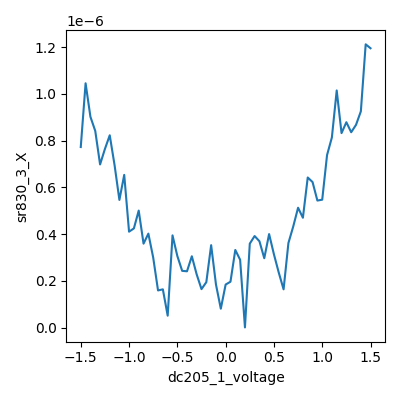

2026-06-21 20:00:38,123 [INFO] Completed in 0h 1m 9s
2026-06-21 20:00:38,123 [INFO] Data saved in C:\Users\toploader\measurements\aaron\20260621-zf1\data\21\data.tsv.gz
2026-06-21 20:00:38,128 [INFO] Ramping dc205_1_voltage: 1.5 -> 0.0
2026-06-21 20:00:38,616 [INFO] Ramping heater_volt: 1.5 -> 0.5
heater=0.5 V  I_heat=1.64e-05 A  T=34 mK
2026-06-21 20:08:40,984 [INFO] Ramping dc205_1_voltage: 0.0 -> -1.5
2026-06-21 20:08:41,458 [INFO] Starting sweep with ID 22
2026-06-21 20:08:41,459 [INFO] Minimum duration 0h 1m 1s


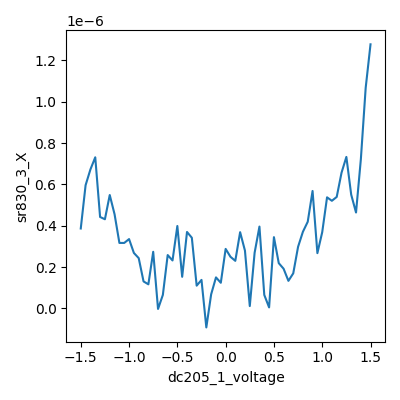

2026-06-21 20:09:51,195 [INFO] Completed in 0h 1m 9s
2026-06-21 20:09:51,195 [INFO] Data saved in C:\Users\toploader\measurements\aaron\20260621-zf1\data\22\data.tsv.gz
2026-06-21 20:09:51,206 [INFO] Ramping dc205_1_voltage: 1.5 -> 0.0
2026-06-21 20:09:51,734 [INFO] Ramping heater_volt: 0.5 -> 0.0
heater=0.0 V  I_heat=2.01e-07 A  T=34 mK
2026-06-21 20:17:53,429 [INFO] Ramping dc205_1_voltage: 0.0 -> -1.5
2026-06-21 20:17:53,879 [INFO] Starting sweep with ID 23
2026-06-21 20:17:53,880 [INFO] Minimum duration 0h 1m 1s


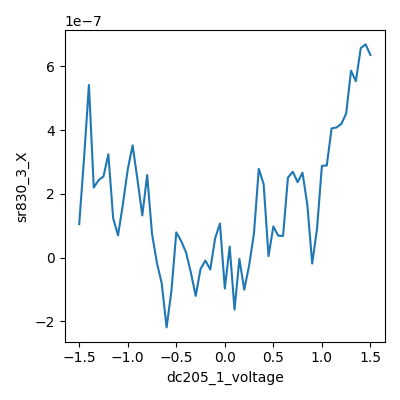

2026-06-21 20:19:03,519 [INFO] Completed in 0h 1m 9s
2026-06-21 20:19:03,520 [INFO] Data saved in C:\Users\toploader\measurements\aaron\20260621-zf1\data\23\data.tsv.gz
2026-06-21 20:19:03,523 [INFO] Ramping dc205_1_voltage: 1.5 -> 0.0


In [23]:
# Tc / I_c(T) ladder at the SC arc minimum (n=-5.02e11, D=-0.673, B=0) — the
# final constellation piece. Flavor B (temperature-dependence.md): warm to the
# top, step the heater DOWN (measure while cooling), dV/dI vs I_dc at each T.
# SC tell: the zero-bias dip / I_c collapses as T -> Tc. Heater per device card
# (<=6.5 V sustained -> ~480 mK). T is read back from data, never the setpoint.
import numpy as np, time

T0=temperature(); B=magnet.field()
print(f"T={T0*1e3:.1f} mK  B={B*1e3:.3f} mT  heater={heater.volt()} V")
assert abs(B)<0.01, f"B not ~0: {B*1e3:.3f} mT"

sr830_1.amplitude(0.05)                      # 0.5 nA AC
for sr in (sr830_1,sr830_3): sr.time_constant(0.3)
sr830_1.sensitivity(1e-3); sr830_3.sensitivity(2e-5)

Vdc=np.linspace(-1.5,1.5,61)                  # +/-15 nA
mc=dict(meas_config); mc["bias_voltage_1"]=sr830_1.amplitude()
s=sweep.AsyncStation(mc)
s.add_comment('temperature-dependence')
s.add_comment('Ic(T) ladder at SC arc min n=-5.02e11 D=-0.673, B=0 (heater down-ladder)')
s.ramp(dc205_1.volt,0.0); s.ramp(k_tg.volt,-5.640); s.ramp(k_bg.volt,4.200)
s.fp(temperature).fp(fridge_temperature).fp(heater.volt).fp(heater.curr)
s.fp(sr830_1.X).fp(sr830_1.P).fp(sr830_3.X).fp(sr830_3.P)
s.plot(dc205_1.volt, sr830_3.X)

for hv in [6.5, 5.5, 4.5, 3.5, 2.5, 1.5, 0.5, 0.0]:    # warm top -> base
    s.ramp(heater.volt, hv); time.sleep(1)
    ic=heater.curr()                                    # open-line check (recipe)
    time.sleep(8*60)                                    # thermalize (read T from data)
    Tnow=temperature()
    print(f"heater={hv:.1f} V  I_heat={ic:.2e} A  T={Tnow*1e3:.0f} mK")
    s.ramp(dc205_1.volt, -1.5)
    s.sweep(dc205_1.volt, Vdc, delay=1.0)               # one file per T
    s.ramp(dc205_1.volt, 0.0)

heater.volt(0.0)                                        # back toward base (re-cool ~1 h)


## HERA — session close / park (optional)

**Result: zf1 (bottom device) is a superconductor** at n≈−5.0×10¹¹, D≈−0.67 V/nm — full call in the ana notebook. This cell parks gates to 0 and zeroes the DC bias for a clean rest (heater already at 0 / re-cooling; magnet at nominal 0 with remanence). **Skip it** if you'd rather hold at SC1 for an immediate follow-up — the two highest-value ones: (1) reproduce the dip on a second voltage pair (7-31) to rule out a probe-local artifact, and (2) re-run the Tc ladder once the temperature worker is restarted, for a quantitative Tc. Both are quick from the current state.


In [24]:
# Session close — park to a safe resting state (optional: skip if you want to
# stay at SC1 for follow-ups like reproducing on pair 7-31 or a re-run Tc once
# the temperature worker is restarted).
import time
s=sweep.AsyncStation(meas_config)
s.ramp(dc205_1.volt, 0.0)        # device-card: zero DC bias
s.ramp(k_tg.volt, 0.0)
s.ramp(k_bg.volt, 0.0)
print("magnet:", magnet.field(), "T (nominal 0, carries remanence)")
print("heater:", heater.volt(), "V ; gates parked to 0 ; DC bias 0")
print("AC drive left at", sr830_1.amplitude(), "V")


2026-06-21 20:42:28,211 [INFO] Ramping dc205_1_voltage: 0.0 -> 0.0
2026-06-21 20:42:28,273 [INFO] Ramping k_tg_volt: -5.64 -> 0.0
2026-06-21 20:42:35,524 [INFO] Ramping k_bg_volt: 4.2 -> 0.0
magnet: 2.21e-07 T (nominal 0, carries remanence)
heater: 0.0 V ; gates parked to 0 ; DC bias 0
AC drive left at 0.05 V
